# A guide Portfolio Optimization Environment

This notebook aims to provide an example of using PortfolioOptimizationEnv (or POE) to train a reinforcement learning model that learns to solve the portfolio optimization problem.

In this document, we will reproduce a famous architecture called EIIE (ensemble of identical independent evaluators), introduced in the following paper:

- Zhengyao Jiang, Dixing Xu, & Jinjun Liang. (2017). A Deep Reinforcement Learning Framework for the Financial Portfolio Management Problem. https://doi.org/10.48550/arXiv.1706.10059.

It's advisable to read it to understand the algorithm implemented in this notebook.

### Note
If you're using this environment, consider citing the following paper (in adittion to FinRL references):

- Caio Costa, & Anna Costa (2023). POE: A General Portfolio Optimization Environment for FinRL. In *Anais do II Brazilian Workshop on Artificial Intelligence in Finance* (pp. 132–143). SBC. https://doi.org/10.5753/bwaif.2023.231144.

```
@inproceedings{bwaif,
 author = {Caio Costa and Anna Costa},
 title = {POE: A General Portfolio Optimization Environment for FinRL},
 booktitle = {Anais do II Brazilian Workshop on Artificial Intelligence in Finance},
 location = {João Pessoa/PB},
 year = {2023},
 keywords = {},
 issn = {0000-0000},
 pages = {132--143},
 publisher = {SBC},
 address = {Porto Alegre, RS, Brasil},
 doi = {10.5753/bwaif.2023.231144},
 url = {https://sol.sbc.org.br/index.php/bwaif/article/view/24959}
}

```

## Installation and imports

To run this notebook in google colab, uncomment the cells below.

In [54]:
## Hide matplotlib warnings
# import warnings
# warnings.filterwarnings('ignore')

import logging
logging.getLogger('matplotlib.font_manager').disabled = True

#### Import the necessary code libraries

In [ ]:
import torch
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from sklearn.preprocessing import MaxAbsScaler

from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import GroupByScaler
from finrl.meta.env_portfolio_optimization.env_portfolio_optimization import PortfolioOptimizationEnv
from finrl.agents.portfolio_optimization.models_raw import DRLAgent
from finrl.agents.portfolio_optimization.architectures_raw import EIIE

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
})

TNR_FONT = FontProperties(family="Times New Roman")
SONGTI_FONT = FontProperties(family="SimSun")

def has_chinese(text):
    text = str(text)
    return any("一" <= ch <= "鿿" for ch in text)

def choose_font(text):
    return SONGTI_FONT if has_chinese(text) else TNR_FONT

def apply_font_to_text(text_obj):
    if text_obj is None:
        return
    text_obj.set_fontproperties(choose_font(text_obj.get_text()))

def apply_times_new_roman(ax):
    apply_font_to_text(ax.title)
    apply_font_to_text(ax.xaxis.label)
    apply_font_to_text(ax.yaxis.label)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        apply_font_to_text(label)
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            apply_font_to_text(text)
        if legend.get_title() is not None:
            apply_font_to_text(legend.get_title())

def apply_times_new_roman_to_legend(legend):
    if legend is not None:
        for text in legend.get_texts():
            apply_font_to_text(text)
        if legend.get_title() is not None:
            apply_font_to_text(legend.get_title())

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

## Fetch data

In his paper, *Jiang et al* creates a portfolio composed by the top-11 cryptocurrencies based on 30-days volume. Since it's not specified when this classification was done, it's difficult to reproduce, so we will use a similar approach in the Brazillian stock market:

- We select top-10 stocks from Brazillian stock market;
- For simplicity, we disconsider stocks that have missing data for the days in period 2011-01-01 to 2019-12-31 (9 years);

In [58]:
TOP_BRL = [
    "VALE3.SA", "PETR4.SA", "ITUB4.SA", "BBDC4.SA",
    "BBAS3.SA", "RENT3.SA", "LREN3.SA", "PRIO3.SA",
    "WEGE3.SA", "ABEV3.SA"
]

In [57]:
%env HTTP_PROXY=http://127.0.0.1:7897
%env HTTPS_PROXY=http://127.0.0.1:7897

env: HTTP_PROXY=http://127.0.0.1:7897
env: HTTPS_PROXY=http://127.0.0.1:7897


In [59]:
print(len(TOP_BRL))

portfolio_raw_df = YahooDownloader(start_date = '2011-01-01',
                                end_date = '2022-12-31',
                                ticker_list = TOP_BRL).fetch_data()
portfolio_raw_df

10


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Shape of DataFrame:  (29780, 8)


Price,date,close,high,low,open,volume,tic,day
0,2011-01-03,4.293335,4.312088,4.263726,4.264713,576145,ABEV3.SA,0
1,2011-01-03,5.564074,5.634953,5.560529,5.581794,6626800,BBAS3.SA,0
2,2011-01-03,5.545342,5.617513,5.521846,5.562126,10862336,BBDC4.SA,0
3,2011-01-03,7.239848,7.312830,7.197883,7.225251,11346613,ITUB4.SA,0
4,2011-01-03,5.218467,5.291593,5.164536,5.164536,4017796,LREN3.SA,0
...,...,...,...,...,...,...,...,...
29775,2022-12-29,13.865267,14.176527,13.825652,14.142572,57901800,PETR4.SA,3
29776,2022-12-29,37.150330,37.419897,36.561276,37.190266,7890300,PRIO3.SA,3
29777,2022-12-29,46.712036,49.135441,46.360817,47.835935,8786791,RENT3.SA,3
29778,2022-12-29,66.229431,67.026747,66.192177,66.318852,40110800,VALE3.SA,3


In [6]:
portfolio_raw_df.groupby("tic").count()

Price,date,close,high,low,open,volume,day
tic,,,,,,,
ABEV3.SA,2978,2978,2978,2978,2978,2978,2978
BBAS3.SA,2978,2978,2978,2978,2978,2978,2978
BBDC4.SA,2978,2978,2978,2978,2978,2978,2978
ITUB4.SA,2978,2978,2978,2978,2978,2978,2978
LREN3.SA,2978,2978,2978,2978,2978,2978,2978
PETR4.SA,2978,2978,2978,2978,2978,2978,2978
PRIO3.SA,2978,2978,2978,2978,2978,2978,2978
RENT3.SA,2978,2978,2978,2978,2978,2978,2978
VALE3.SA,2978,2978,2978,2978,2978,2978,2978


### Normalize Data

We normalize the data dividing the time series of each stock by its maximum value, so that the dataframe contains values between 0 and 1.

In [60]:
portfolio_norm_df = GroupByScaler(by="tic", scaler=MaxAbsScaler).fit_transform(portfolio_raw_df)
portfolio_norm_df

c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.00200262 0.00114137 0.0010422  ... 0.04565734 0.05214546 0.07760399]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(
c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.   0.25 0.5  ... 0.25 0.5  0.75]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(


Price,date,close,high,low,open,volume,tic,day
0,2011-01-03,0.266099,0.264105,0.266903,0.263025,0.002003,ABEV3.SA,0.00
1,2011-01-03,0.321735,0.323948,0.326813,0.323460,0.014581,BBAS3.SA,0.00
2,2011-01-03,0.292123,0.291997,0.293792,0.291601,0.021760,BBDC4.SA,0.00
3,2011-01-03,0.312009,0.313424,0.315005,0.315202,0.062331,ITUB4.SA,0.00
4,2011-01-03,0.128688,0.130427,0.129054,0.127421,0.072591,LREN3.SA,0.00
...,...,...,...,...,...,...,...,...
29775,2022-12-29,0.694899,0.698099,0.718239,0.732488,0.082841,PETR4.SA,0.75
29776,2022-12-29,0.857373,0.844144,0.878173,0.858295,0.048724,PRIO3.SA,0.75
29777,2022-12-29,0.728877,0.759975,0.732256,0.747023,0.097191,RENT3.SA,0.75
29778,2022-12-29,0.916710,0.920399,0.932491,0.911700,0.218546,VALE3.SA,0.75


In [61]:
df_portfolio = portfolio_norm_df[["date", "tic", "close", "high", "low"]]

# 训练集：2011-2018
df_portfolio_train = df_portfolio[
    (df_portfolio["date"] >= "2011-01-01") & 
    (df_portfolio["date"] < "2019-01-01")
]

# 验证集：2019全年（从训练集末尾切出来）
df_portfolio_val = df_portfolio[
    (df_portfolio["date"] >= "2019-01-01") & 
    (df_portfolio["date"] < "2020-01-01")
]

# 测试集不变
df_portfolio_2020 = df_portfolio[
    (df_portfolio["date"] >= "2020-01-01") & 
    (df_portfolio["date"] < "2021-01-01")
]
df_portfolio_2021 = df_portfolio[
    (df_portfolio["date"] >= "2021-01-01") & 
    (df_portfolio["date"] < "2022-01-01")
]
df_portfolio_2022 = df_portfolio[
    (df_portfolio["date"] >= "2022-01-01") & 
    (df_portfolio["date"] < "2023-01-01")
]

### Instantiate Environment

Using the `PortfolioOptimizationEnv`, it's easy to instantiate a portfolio optimization environment for reinforcement learning agents. In the example below, we use the dataframe created before to start an environment.

In [63]:
environment = PortfolioOptimizationEnv(
        df_portfolio_train,
        initial_amount=100000,
        comission_fee_pct=0.0025,
        time_window=50,
        features=["close", "high", "low"],
        normalize_df=None
    )

# 验证集环境（参数与训练环境保持一致）
environment_val = PortfolioOptimizationEnv(
        df_portfolio_val,
        initial_amount=100000,
        comission_fee_pct=0.0025,
        time_window=50,
        features=["close", "high", "low"],
        normalize_df=None
)


### Instantiate Model

Now, we can instantiate the model using FinRL API. In this example, we are going to use the EIIE architecture introduced by Jiang et. al.

:exclamation: **Note:** Remember to set the architecture's `time_window` parameter with the same value of the environment's `time_window`.

In [85]:
# set PolicyGradient parameters
model_kwargs = {
    "lr": 0.005,
    "policy": EIIE,
}

# here, we can set EIIE's parameters
policy_kwargs = {
    "k_size": 3,
    "time_window": 50,
}

model = DRLAgent(environment).get_model("pg", device, model_kwargs, policy_kwargs)

### Train Model

In [86]:
import torch
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import copy

def calculate_sharpe(value_list, risk_free_rate=0, periods_per_year=252):
    """从组合净值序列计算年化 Sharpe Ratio（无风险利率默认2%）"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    if daily_returns.std() == 0:
        return 0.0
    excess = daily_returns.mean() - risk_free_rate / periods_per_year
    return (excess / daily_returns.std()) * np.sqrt(periods_per_year)

def calculate_metrics(value_list, risk_free_rate=0, periods_per_year=252):
    """计算完整指标：累计收益、年化收益、波动率、Sharpe、最大回撤、Calmar"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    
    total_return   = (values[-1] / values[0]) - 1
    n_days         = len(values) - 1
    annual_return  = (1 + total_return) ** (periods_per_year / n_days) - 1
    annual_vol     = daily_returns.std() * np.sqrt(periods_per_year)
    
    excess         = daily_returns.mean() - risk_free_rate / periods_per_year
    sharpe         = (excess / daily_returns.std()) * np.sqrt(periods_per_year) if daily_returns.std() != 0 else 0.0
    
    cumulative     = values / values[0]
    rolling_max    = np.maximum.accumulate(cumulative)
    drawdown       = (cumulative - rolling_max) / rolling_max
    max_drawdown   = drawdown.min()
    calmar         = annual_return / abs(max_drawdown) if max_drawdown != 0 else 0.0
    
    return {
        "累计收益":   round(total_return,  4),
        "年化收益":   round(annual_return, 4),
        "年化波动率": round(annual_vol,    4),
        "Sharpe":    round(sharpe,        4),
        "最大回撤":   round(max_drawdown,  4),
        "Calmar":    round(calmar,        4),
    }

# ── Early Stop 配置 ──────────────────────────────────────
MAX_EPISODES   = 40    # 最大训练轮数（可根据算力调整）
PATIENCE       = 3    # 连续多少轮验证集无改善则停止
SAVE_PATH      = "policy_EIIE_bitcoin_best.pt"

# ── 训练状态 ─────────────────────────────────────────────
best_val_sharpe  = -np.inf
best_episode     = 0
patience_counter = 0
history = {"val_sharpe": [], "val_return": []}

print(f"开始训练，最大轮数={MAX_EPISODES}，早停耐心值={PATIENCE}")
print("-" * 60)

for episode in range(1, MAX_EPISODES + 1):

    # 1. 训练一个 episode
    DRLAgent.train_model(model, episodes=1)

    # 2. 在验证集上评估
    DRLAgent.DRL_validation(model, environment_val, policy=model.train_policy)
    val_values = environment_val._asset_memory["final"]

    val_sharpe = calculate_sharpe(val_values)
    val_return = (val_values[-1] / val_values[0]) - 1
    history["val_sharpe"].append(val_sharpe)
    history["val_return"].append(val_return)

    print(f"第{episode:3d}轮 | 验证集 Sharpe: {val_sharpe:+.4f} | "
          f"验证集收益: {val_return:+.4f} | 历史最优: {best_val_sharpe:+.4f}（第{best_episode}轮）")

    # 3. 保存最优 checkpoint
    if val_sharpe > best_val_sharpe:
        best_val_sharpe  = val_sharpe
        best_episode     = episode
        patience_counter = 0
        torch.save(model.train_policy.state_dict(), SAVE_PATH)
        print(f"  ✓ 验证集 Sharpe 创新高，已保存最优模型 → {SAVE_PATH}")
    else:
        patience_counter += 1
        print(f"  耐心计数：{patience_counter}/{PATIENCE}")

    # 4. Early stopping
    if patience_counter >= PATIENCE:
        print(f"早停触发（第{episode}轮）")
        print(f"   最优轮次：第{best_episode}轮 | 验证集 Sharpe：{best_val_sharpe:.4f}")
        break

print("训练结束，加载最优权重...")
policy = EIIE(time_window=50, device=device)
policy.load_state_dict(torch.load(SAVE_PATH))
print(f"已加载最优模型（来自第{best_episode}轮，验证集 Sharpe = {best_val_sharpe:.4f}）")



开始训练，最大轮数=40，早停耐心值=3
------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

Initial portfolio value:100000
Final portfolio value: 246001.84375
Final accumulative portfolio value: 2.4600184375
Maximum DrawDown: -0.4461709336137465
Sharpe ratio: 0.6324467897635181


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)
100%|██████████| 1/1 [00:29<00:00, 29.58s/it]


Initial portfolio value:100000
Final portfolio value: 124924.9921875
Final accumulative portfolio value: 1.249249921875
Maximum DrawDown: -0.1047356013796149
Sharpe ratio: 1.8065706237615557


...

c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)
100%|██████████| 1/1 [00:29<00:00, 29.93s/it]


Initial portfolio value:100000
Final portfolio value: 132968.203125
Final accumulative portfolio value: 1.32968203125
Maximum DrawDown: -0.10966744006187157
Sharpe ratio: 2.199228842545143


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


第  8轮 | 验证集 Sharpe: +2.2104 | 验证集收益: +0.3297 | 历史最优: +2.2867（第5轮）
  耐心计数：3/3
早停触发（第8轮）
   最优轮次：第5轮 | 验证集 Sharpe：2.2867
训练结束，加载最优权重...
已加载最优模型（来自第5轮，验证集 Sharpe = 2.2867）


C:\Users\64954\AppData\Local\Temp\ipykernel_41104\3400223814.py:95: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load(SAVE_PATH))


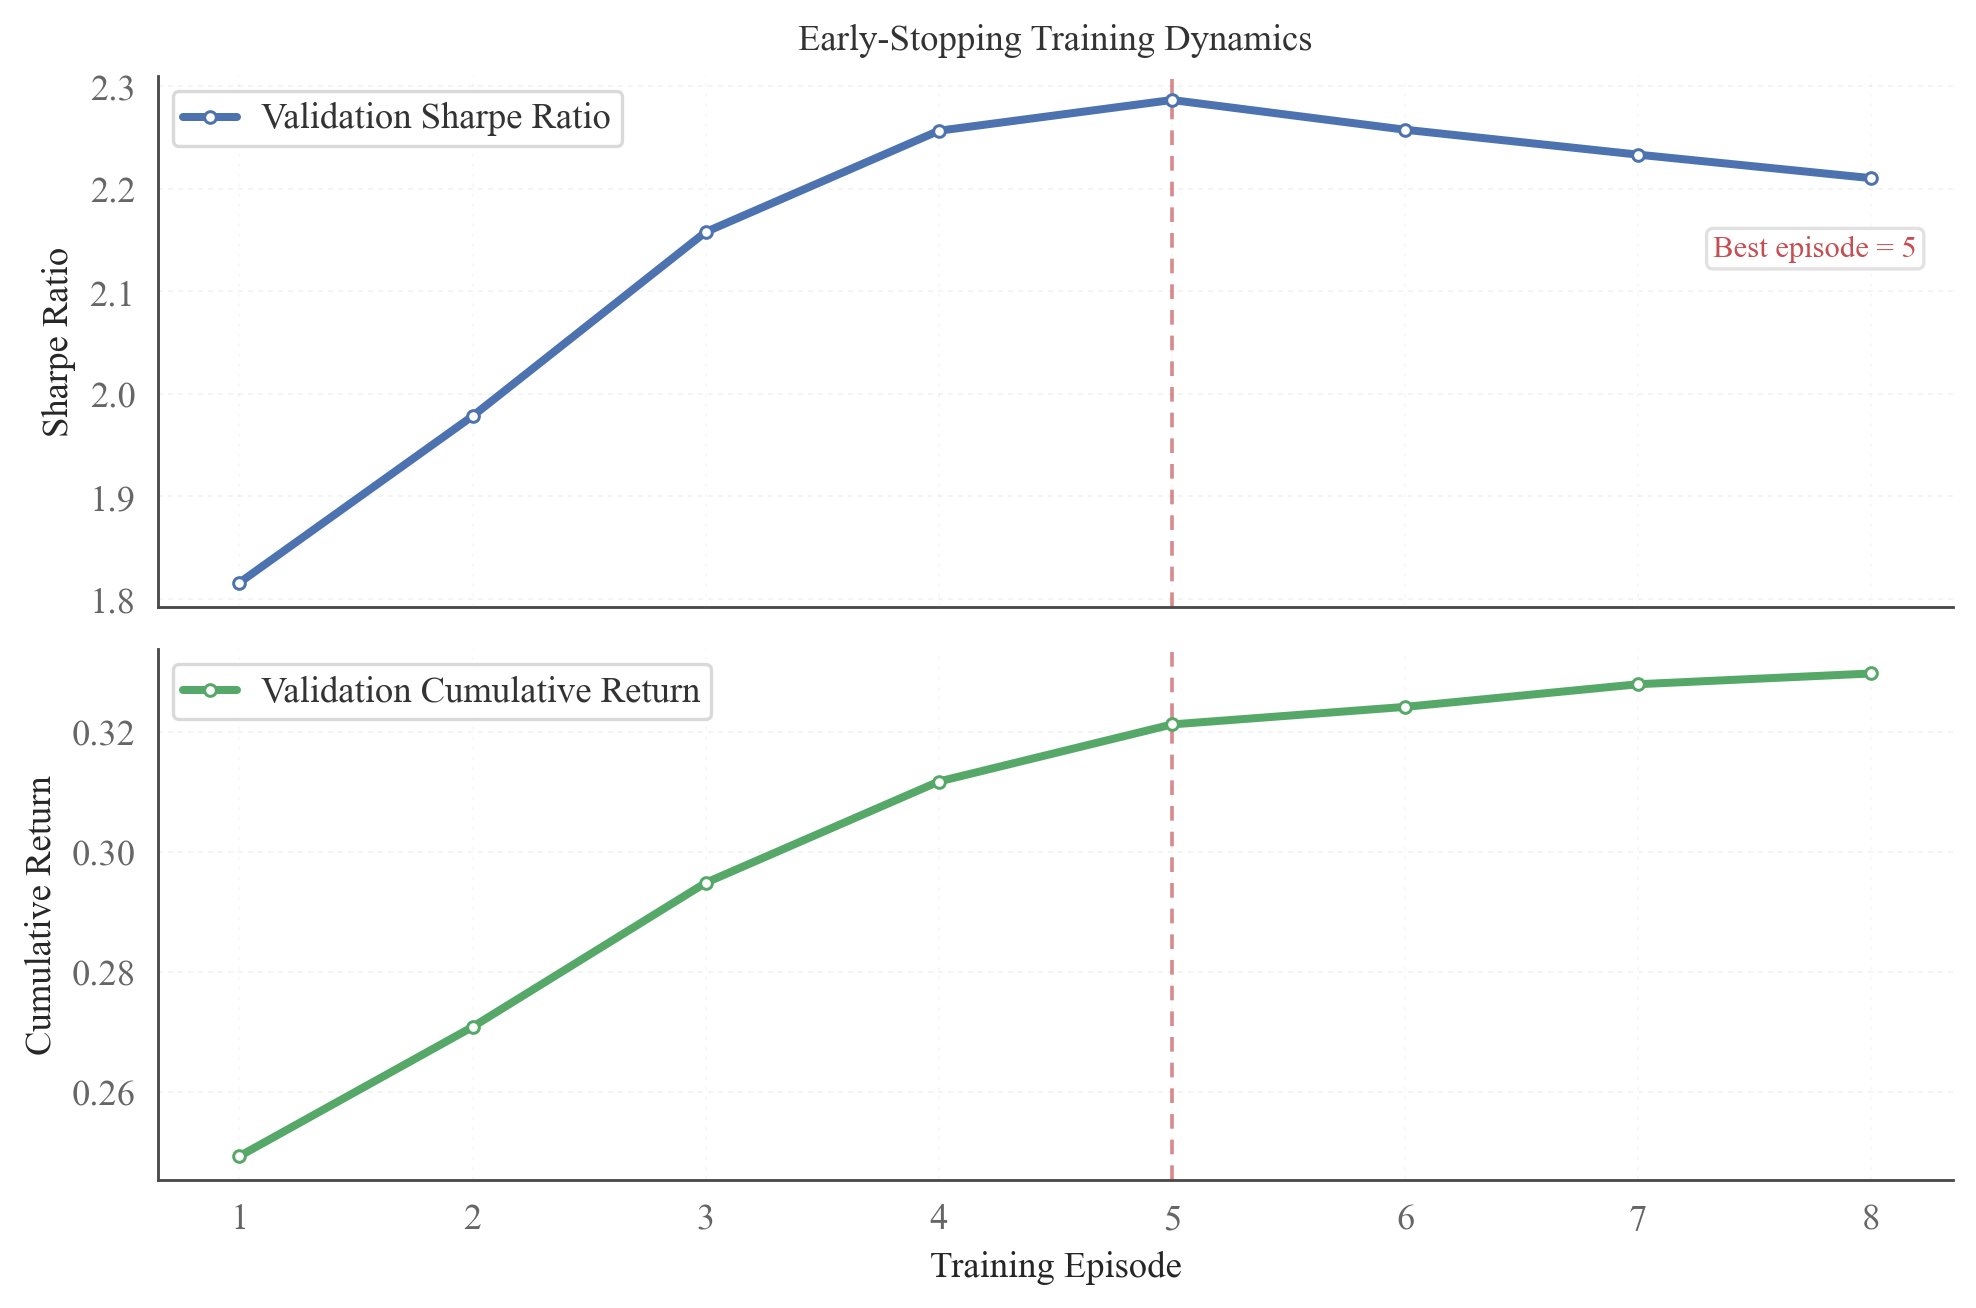

Training curves saved to: raw_EIIE_bitcoin_figures\training_curve.png


In [87]:
%config InlineBackend.figure_format = 'retina'

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

output_dir = "raw_EIIE_bitcoin_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,

    "axes.linewidth": 0.85,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.18,
    "lines.linewidth": 2.4,
})

COLOR_SHARPE = "#4C72B0"
COLOR_RETURN = "#55A868"
COLOR_BEST = "#C44E52"
GRID_COLOR = "#B8B8B8"
SPINE_COLOR = "#4A4A4A"

episodes = np.arange(1, len(history["val_sharpe"]) + 1)
best_x = best_episode

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(8.8, 5.9),
    sharex=True,
    gridspec_kw={"hspace": 0.08}
)

# Top panel: validation Sharpe ratio
ax1.plot(
    episodes,
    history["val_sharpe"],
    color=COLOR_SHARPE,
    marker="o",
    markersize=3.5,
    markerfacecolor="white",
    markeredgewidth=0.9,
    label="Validation Sharpe Ratio",
    zorder=3
)
ax1.axvline(
    best_x,
    color=COLOR_BEST,
    linestyle=(0, (4, 3)),
    linewidth=1.1,
    alpha=0.65,
    zorder=2
)
ax1.set_ylabel("Sharpe Ratio")
ax1.set_title("Early-Stopping Training Dynamics", pad=8)

ax1.grid(True, axis="y", linestyle=(0, (3, 3)), color=GRID_COLOR)
ax1.grid(True, axis="x", linestyle=(0, (2, 4)), color=GRID_COLOR, alpha=0.10)
ax1.set_axisbelow(True)

ax1.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#D6D6D6",
    borderpad=0.35,
    handlelength=1.8
)

ax1.text(
    0.98, 0.7,
    f"Best episode = {best_episode}",
    transform=ax1.transAxes,
    ha="right",
    va="top",
    fontsize=9.2,
    color=COLOR_BEST,
    bbox=dict(
        boxstyle="round,pad=0.22",
        facecolor="white",
        edgecolor="#DDDDDD",
        alpha=0.88
    )
)

# Bottom panel: validation cumulative return
ax2.plot(
    episodes,
    history["val_return"],
    color=COLOR_RETURN,
    marker="o",
    markersize=3.5,
    markerfacecolor="white",
    markeredgewidth=0.9,
    label="Validation Cumulative Return",
    zorder=3
)
ax2.axvline(
    best_x,
    color=COLOR_BEST,
    linestyle=(0, (4, 3)),
    linewidth=1.1,
    alpha=0.65,
    zorder=2
)
ax2.set_ylabel("Cumulative Return")
ax2.set_xlabel("Training Episode")

ax2.grid(True, axis="y", linestyle=(0, (3, 3)), color=GRID_COLOR)
ax2.grid(True, axis="x", linestyle=(0, (2, 4)), color=GRID_COLOR, alpha=0.10)
ax2.set_axisbelow(True)

ax2.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#D6D6D6",
    borderpad=0.35,
    handlelength=1.8
)

# Integer episode ticks
ax2.set_xticks(episodes)

# Spine and tick styling
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(SPINE_COLOR)
    ax.spines["bottom"].set_color(SPINE_COLOR)
    ax.tick_params(
        axis="both",
        which="major",
        length=3.2,
        width=0.75,
        color=SPINE_COLOR
    )
    apply_times_new_roman(ax)

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    top=0.90,
    bottom=0.12,
    hspace=0.08
)

png_path = os.path.join(output_dir, "training_curve.png")
fig.savefig(png_path, bbox_inches="tight")

plt.show()
print("Training curves saved to:", png_path)


### Save Model

In [ ]:
# torch.save(model.train_policy.state_dict(), "policy_EIIE.pt")

## Test Model

### Instantiate different environments

Since we have three different periods of time, we need three different environments instantiated to simulate them.

In [88]:
environment_2020 = PortfolioOptimizationEnv(
    df_portfolio_2020,
    initial_amount=100000,
    comission_fee_pct=0.0025,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

environment_2021 = PortfolioOptimizationEnv(
    df_portfolio_2021,
    initial_amount=100000,
    comission_fee_pct=0.0025,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

environment_2022 = PortfolioOptimizationEnv(
    df_portfolio_2022,
    initial_amount=100000,
    comission_fee_pct=0.0025,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

### Test EIIE architecture
Now, we can test the EIIE architecture in the three different test periods. It's important no note that, in this code, we load the saved policy even though it's not necessary just to show how to save and load your model.

In [ ]:
# import numpy as np

# def calculate_sharpe(value_list, risk_free_rate=0.0, periods_per_year=252):
#     """
#     从portfolio value序列计算年化Sharpe Ratio
#     value_list: 每日组合净值列表
#     """
#     values = np.array(value_list)
#     # 计算每日收益率
#     daily_returns = np.diff(values) / values[:-1]
    
#     if daily_returns.std() == 0:
#         return 0.0
    
#     # 年化Sharpe
#     sharpe = (daily_returns.mean() - risk_free_rate / periods_per_year) / daily_returns.std()
#     sharpe_annualized = sharpe * np.sqrt(periods_per_year)
#     return sharpe_annualized

In [89]:
import numpy as np

EIIE_results = {
    "training": environment._asset_memory["final"],
    "validation": {"value": list(environment_val._asset_memory["final"])},
    "2020": {},
    "2021": {},
    "2022": {}
}

# instantiate an architecture with the same arguments used in training
# and load with load_state_dict.
policy = EIIE(time_window=50, device=device)
policy.load_state_dict(torch.load("policy_EIIE_bitcoin_best.pt"))

# 2020
DRLAgent.DRL_validation(model, environment_2020, policy=policy)
for year, env in [("2020", environment_2020),
                  ("2021", environment_2021),
                  ("2022", environment_2022)]:
    DRLAgent.DRL_validation(model, env, policy=policy)
    values = env._asset_memory["final"]
    actions = np.array(env._actions_memory).copy()
    turnover = np.sum(np.abs(np.diff(actions[:, 1:], axis=0)), axis=1)
    EIIE_results[year] = {
        "value":   list(values),
        "actions": np.array(env._actions_memory).copy(),
        "turnover": turnover
    }

C:\Users\64954\AppData\Local\Temp\ipykernel_41104\1293995872.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load("policy_EIIE_bitcoin_best

Initial portfolio value:100000
Final portfolio value: 199607.546875
Final accumulative portfolio value: 1.99607546875
Maximum DrawDown: -0.20859992187499998
Sharpe ratio: 2.369171114970807


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 199607.546875
Final accumulative portfolio value: 1.99607546875
Maximum DrawDown: -0.20859992187499998
Sharpe ratio: 2.369171114970807


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 103212.1953125
Final accumulative portfolio value: 1.032121953125
Maximum DrawDown: -0.1011778351542143
Sharpe ratio: 0.3250166508812111


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 111261.8125
Final accumulative portfolio value: 1.112618125
Maximum DrawDown: -0.12298568464739645
Sharpe ratio: 0.9151916325211167


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


### Test Uniform Buy and Hold
For comparison, we will also test the performance of a uniform buy and hold strategy. In this strategy, the portfolio has no remaining cash and the same percentage of money is allocated in each asset.

In [90]:
EW_results = {
    "train": {},
    "validation": {},
    "2020": {},
    "2021": {},
    "2022": {}
}

PORTFOLIO_SIZE = len(TOP_BRL)

# train period
terminated = False
environment.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment.step(action)
EW_results["train"]["value"] = environment._asset_memory["final"]

# validation period
terminated = False
environment_val.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_val.step(action)
EW_results["validation"]["value"] = environment_val._asset_memory["final"]

# 2020
terminated = False
environment_2020.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2020.step(action)
EW_results["2020"]["value"] = environment_2020._asset_memory["final"]

# 2021
terminated = False
environment_2021.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2021.step(action)
EW_results["2021"]["value"] = environment_2021._asset_memory["final"]

# 2022
terminated = False
environment_2022.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2022.step(action)
EW_results["2022"]["value"] = environment_2022._asset_memory["final"]

Initial portfolio value:100000
Final portfolio value: 264105.09375
Final accumulative portfolio value: 2.6410509375
Maximum DrawDown: -0.47863845957144935
Sharpe ratio: 0.6332642115582557


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 126368.53125
Final accumulative portfolio value: 1.2636853125
Maximum DrawDown: -0.11628059691809245
Sharpe ratio: 1.707234936852847


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 170950.359375
Final accumulative portfolio value: 1.70950359375
Maximum DrawDown: -0.250789140625
Sharpe ratio: 1.7098052098146594


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 95715.4296875
Final accumulative portfolio value: 0.957154296875
Maximum DrawDown: -0.17293104749945276
Sharpe ratio: -0.1563956173506107


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 113960.7890625
Final accumulative portfolio value: 1.139607890625
Maximum DrawDown: -0.16618937850366222
Sharpe ratio: 0.8342244685756303


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


### Plot graphics

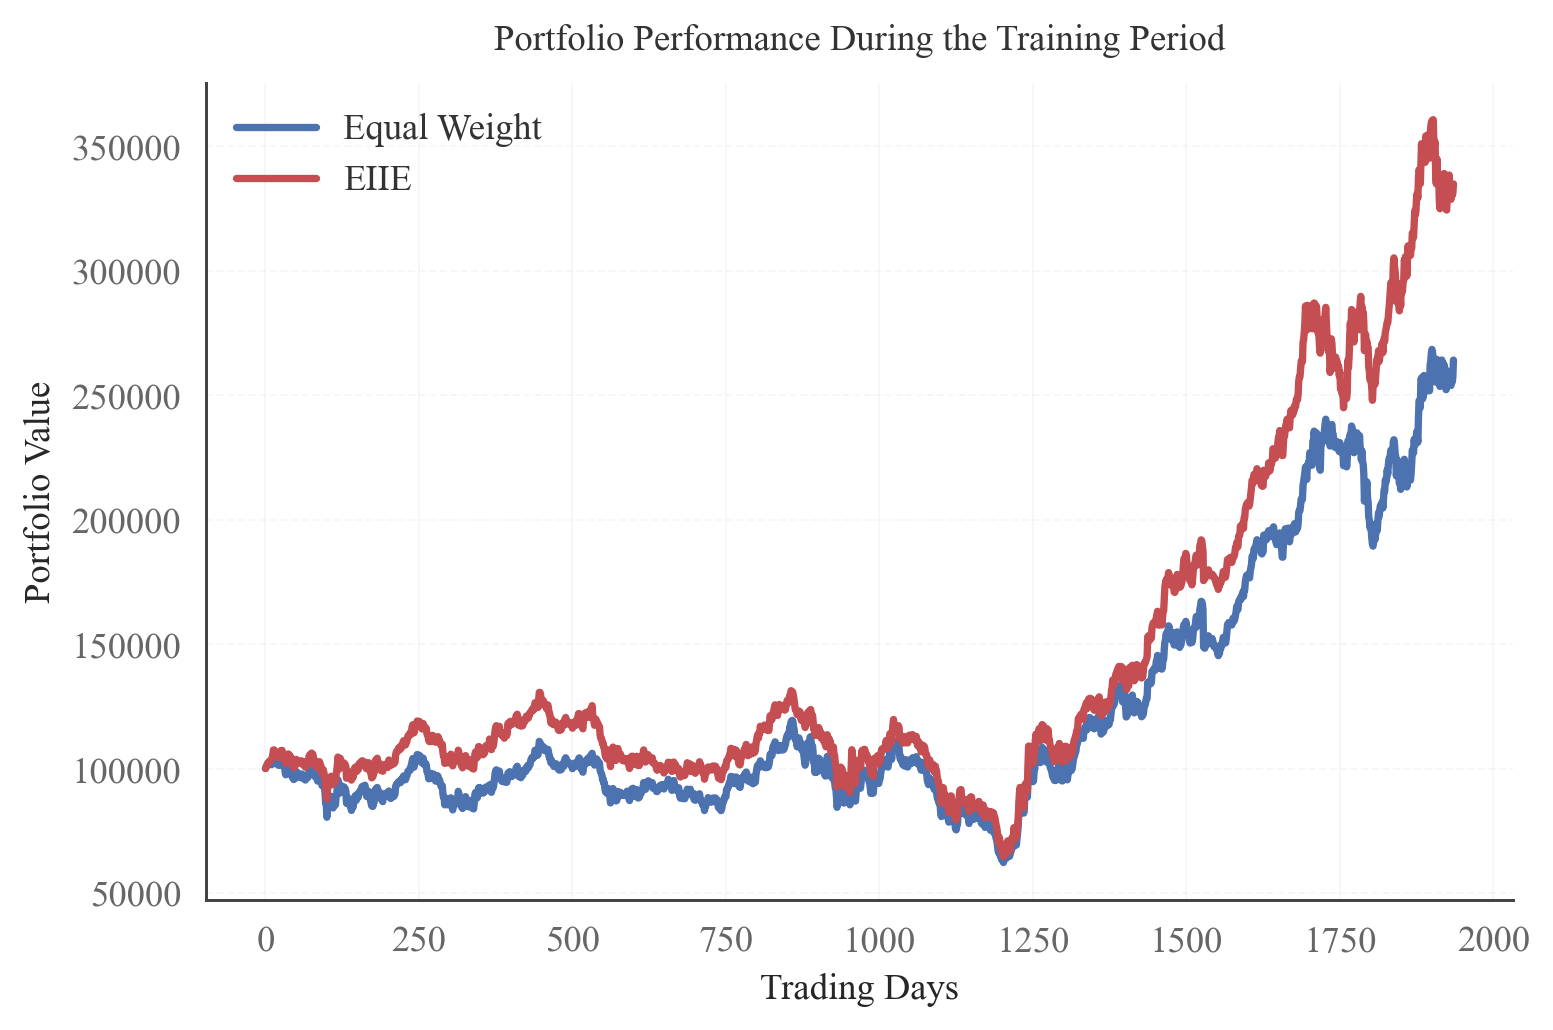

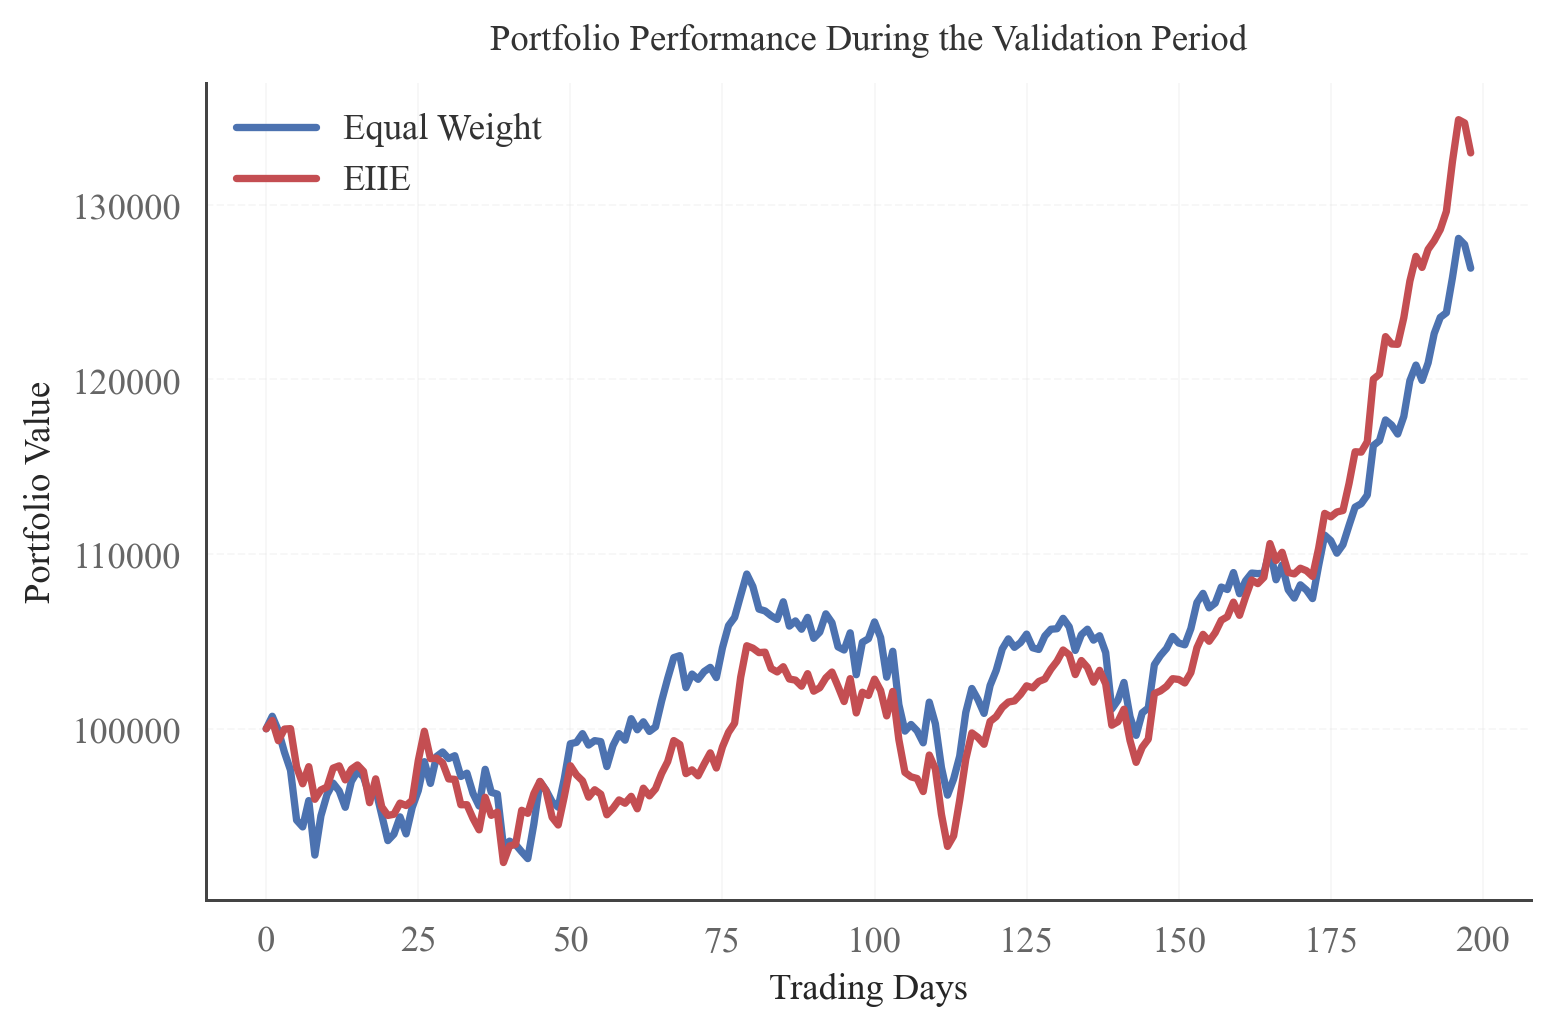

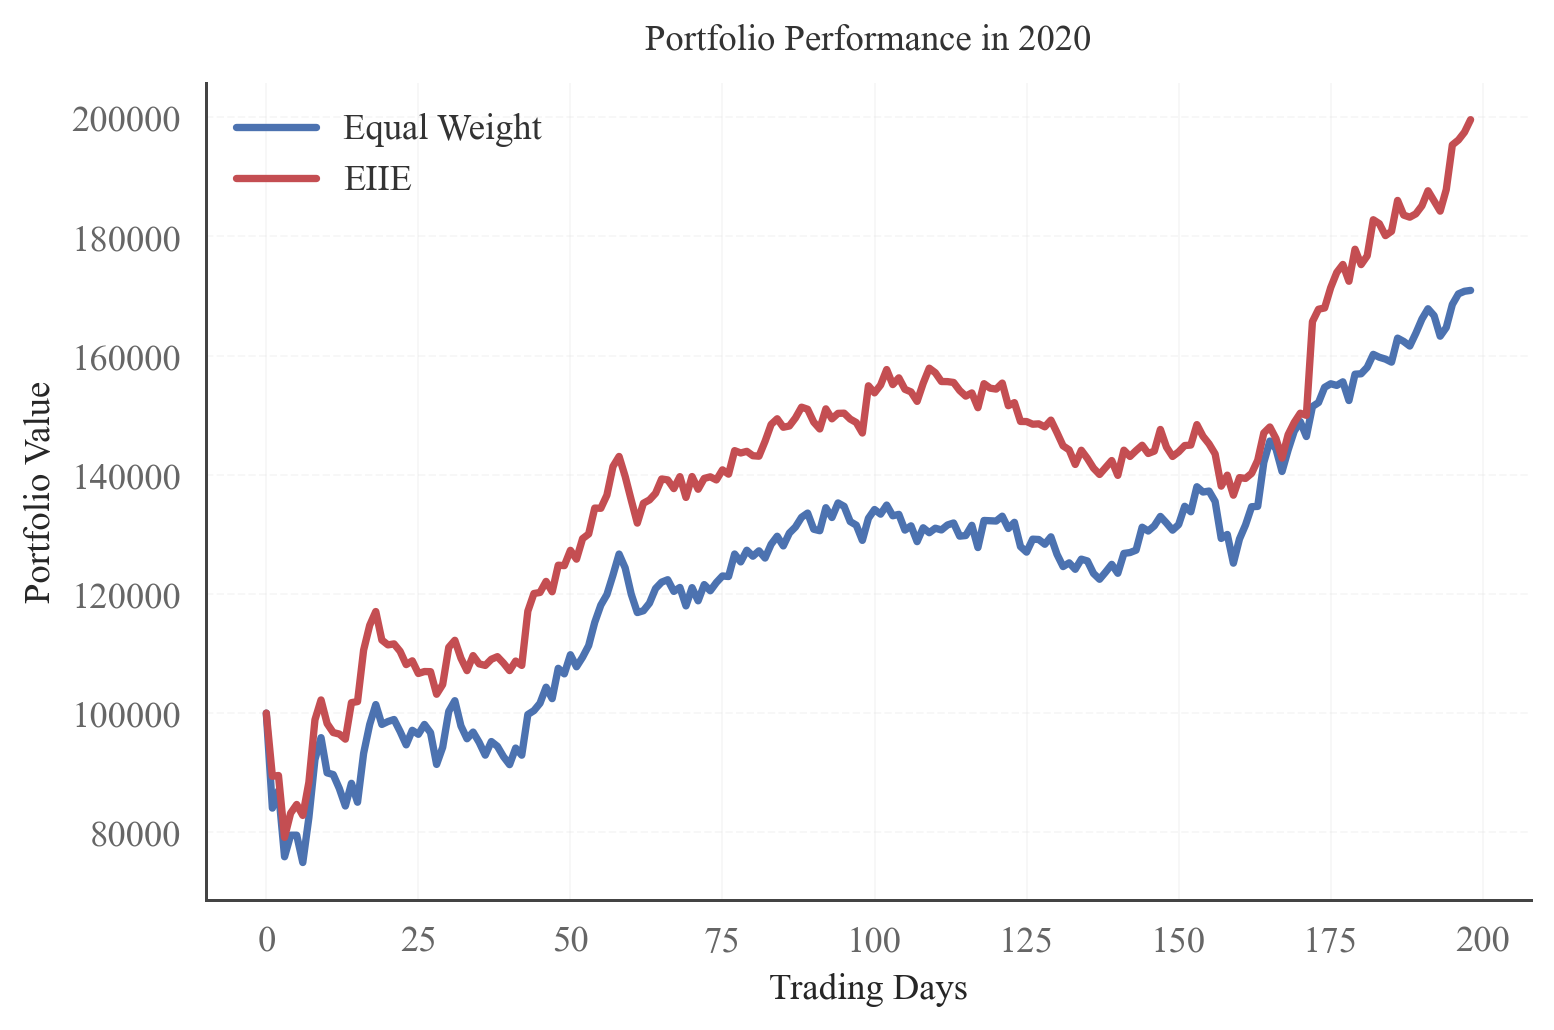

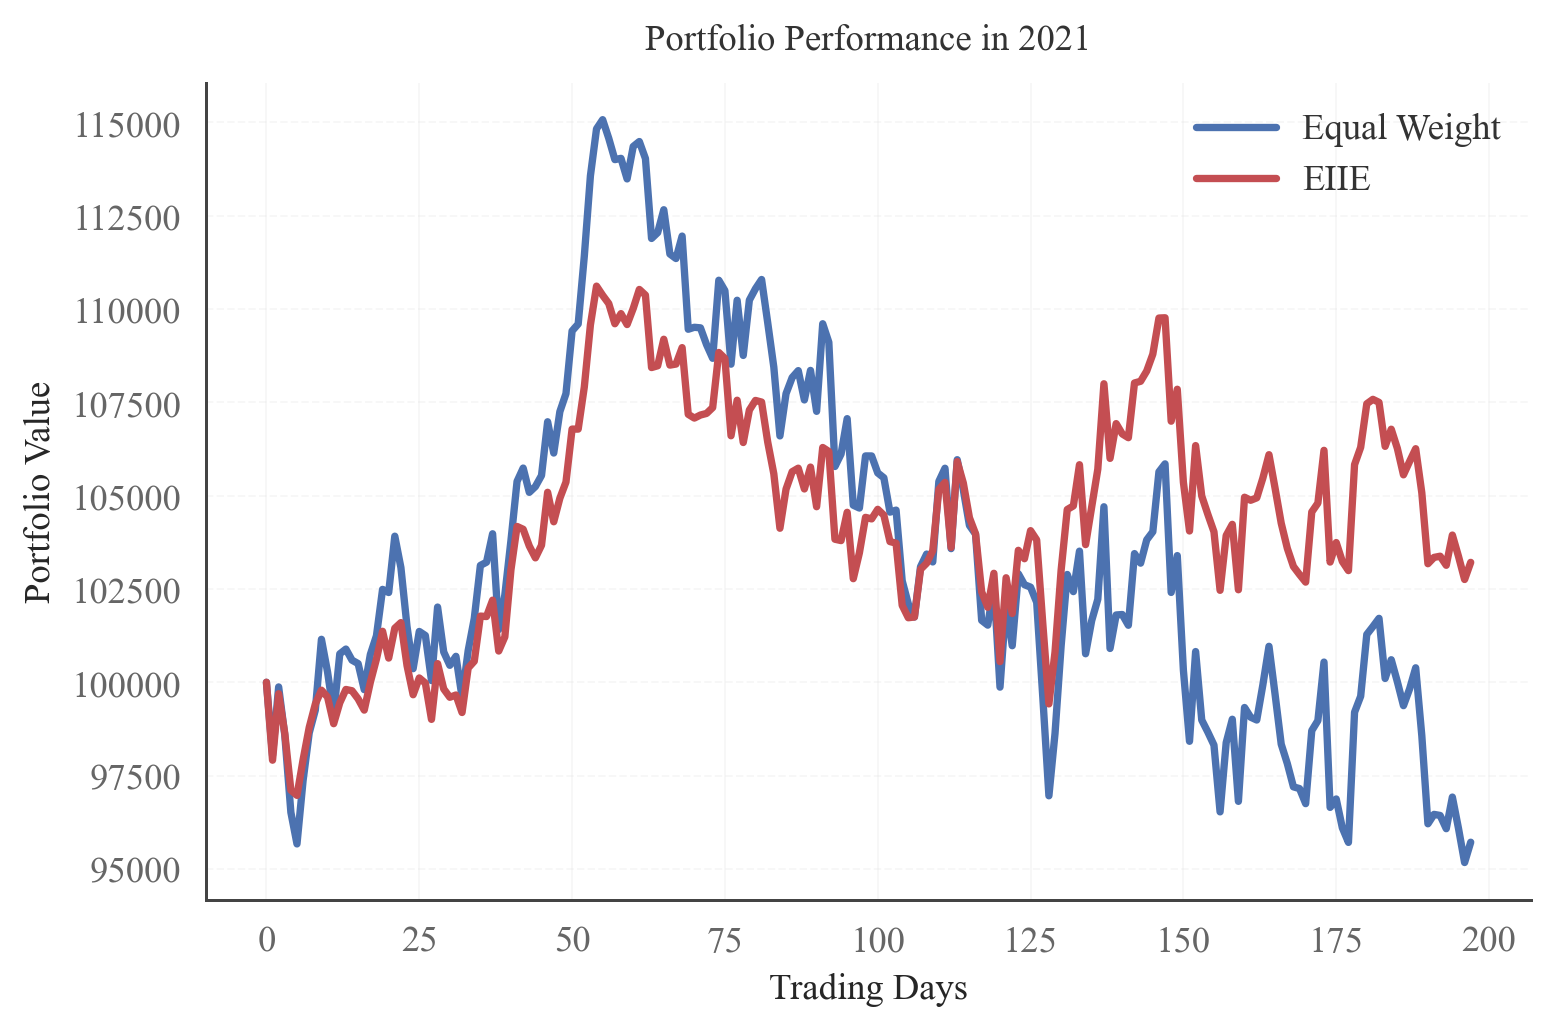

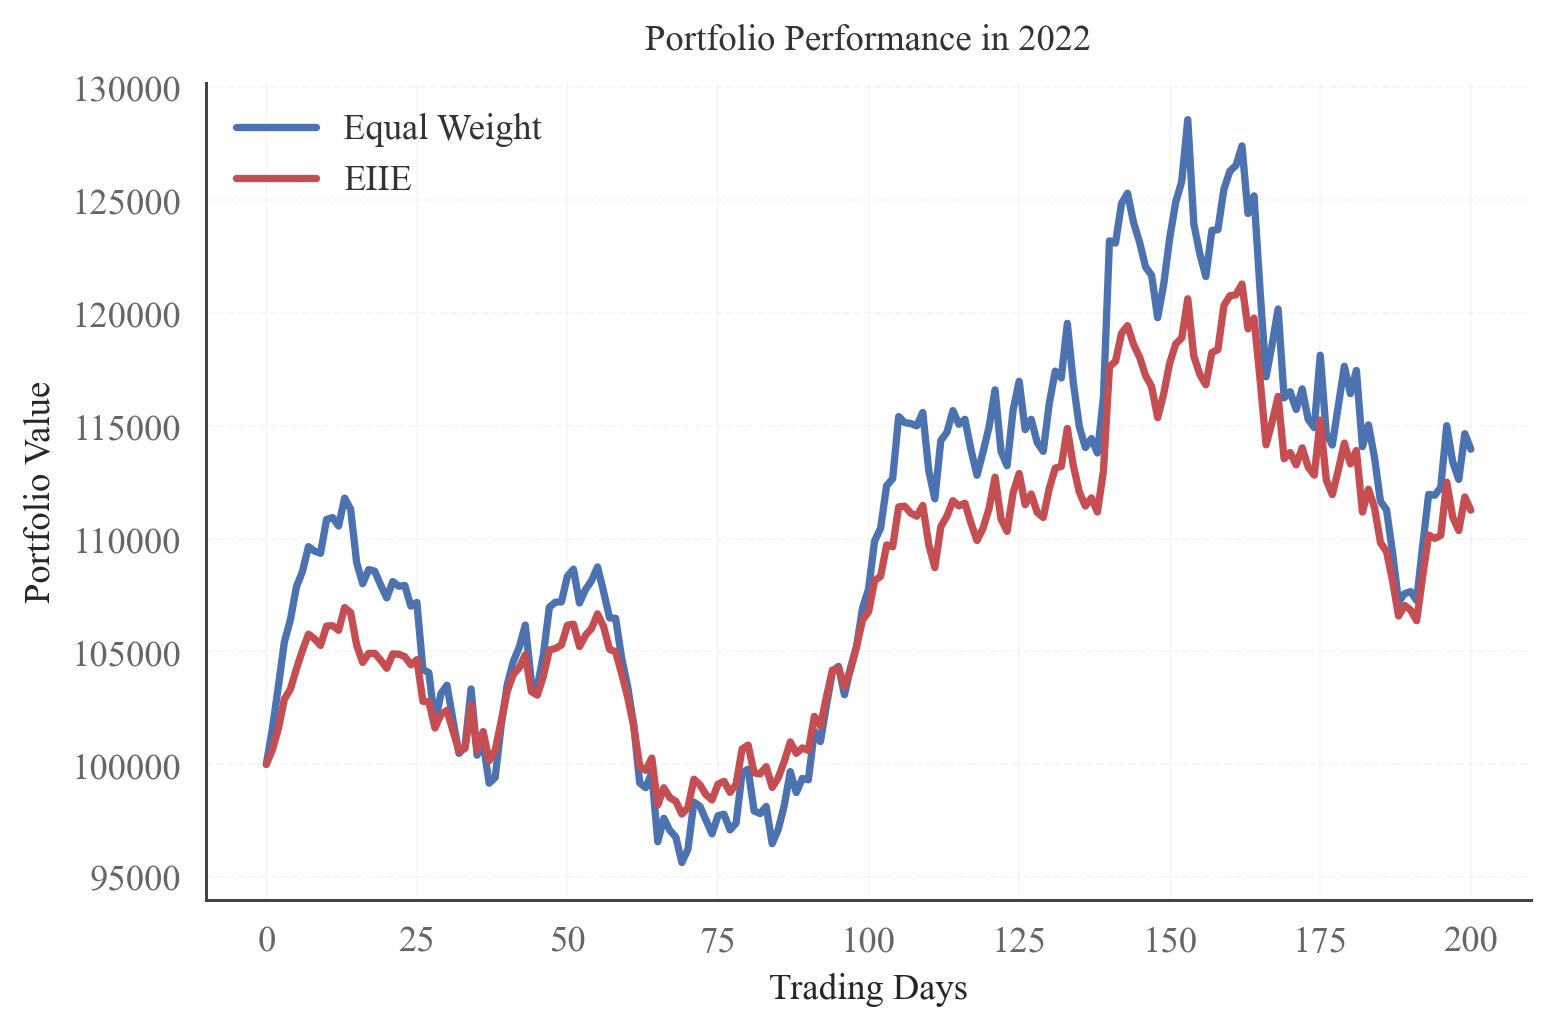

In [91]:
import matplotlib.pyplot as plt
import os
%matplotlib inline 

output_dir = "raw_EIIE_bitcoin_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,

    "figure.figsize": (6.6, 4.4),
    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,

    "lines.linewidth": 2.4,
    "axes.linewidth": 0.9,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "legend.frameon": False,
    "legend.handlelength": 2.4,

    "grid.alpha": 0.22,
    "grid.linewidth": 0.6,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# Academic-style muted palette
COLOR_EW = "#4C72B0"
COLOR_EIIE = "#C44E52"

def plot_portfolio_value(ew_values, eiie_values, title, save_name=None):
    fig, ax = plt.subplots()

    x_ew = np.arange(len(ew_values))
    x_eiie = np.arange(len(eiie_values))

    ax.plot(
        x_ew,
        ew_values,
        label="Equal Weight",
        color=COLOR_EW,
        linewidth=2.2
    )
    ax.plot(
        x_eiie,
        eiie_values,
        label="EIIE",
        color=COLOR_EIIE,
        linewidth=2.2
    )

    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Portfolio Value")
    ax.set_title(title, pad=10)

    ax.grid(True, axis="y", linestyle="--")
    ax.legend(loc="best")

    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=4, width=0.8, color="#444444")

    apply_times_new_roman(ax)
    plt.tight_layout()

    if save_name is not None:
        fig.savefig(os.path.join(output_dir, f"{save_name}.png"), bbox_inches="tight")

    plt.show()


plot_portfolio_value(
    EW_results["train"]["value"],
    EIIE_results["training"],
    title="Portfolio Performance During the Training Period",
    save_name="value_train"
)

plot_portfolio_value(
    EW_results["validation"]["value"],
    EIIE_results["validation"]["value"],
    title="Portfolio Performance During the Validation Period",
    save_name="value_validation"
)

plot_portfolio_value(
    EW_results["2020"]["value"],
    EIIE_results["2020"]["value"],
    title="Portfolio Performance in 2020",
    save_name="value_2020"
)

plot_portfolio_value(
    EW_results["2021"]["value"],
    EIIE_results["2021"]["value"],
    title="Portfolio Performance in 2021",
    save_name="value_2021"
)

plot_portfolio_value(
    EW_results["2022"]["value"],
    EIIE_results["2022"]["value"],
    title="Portfolio Performance in 2022",
    save_name="value_2022"
)

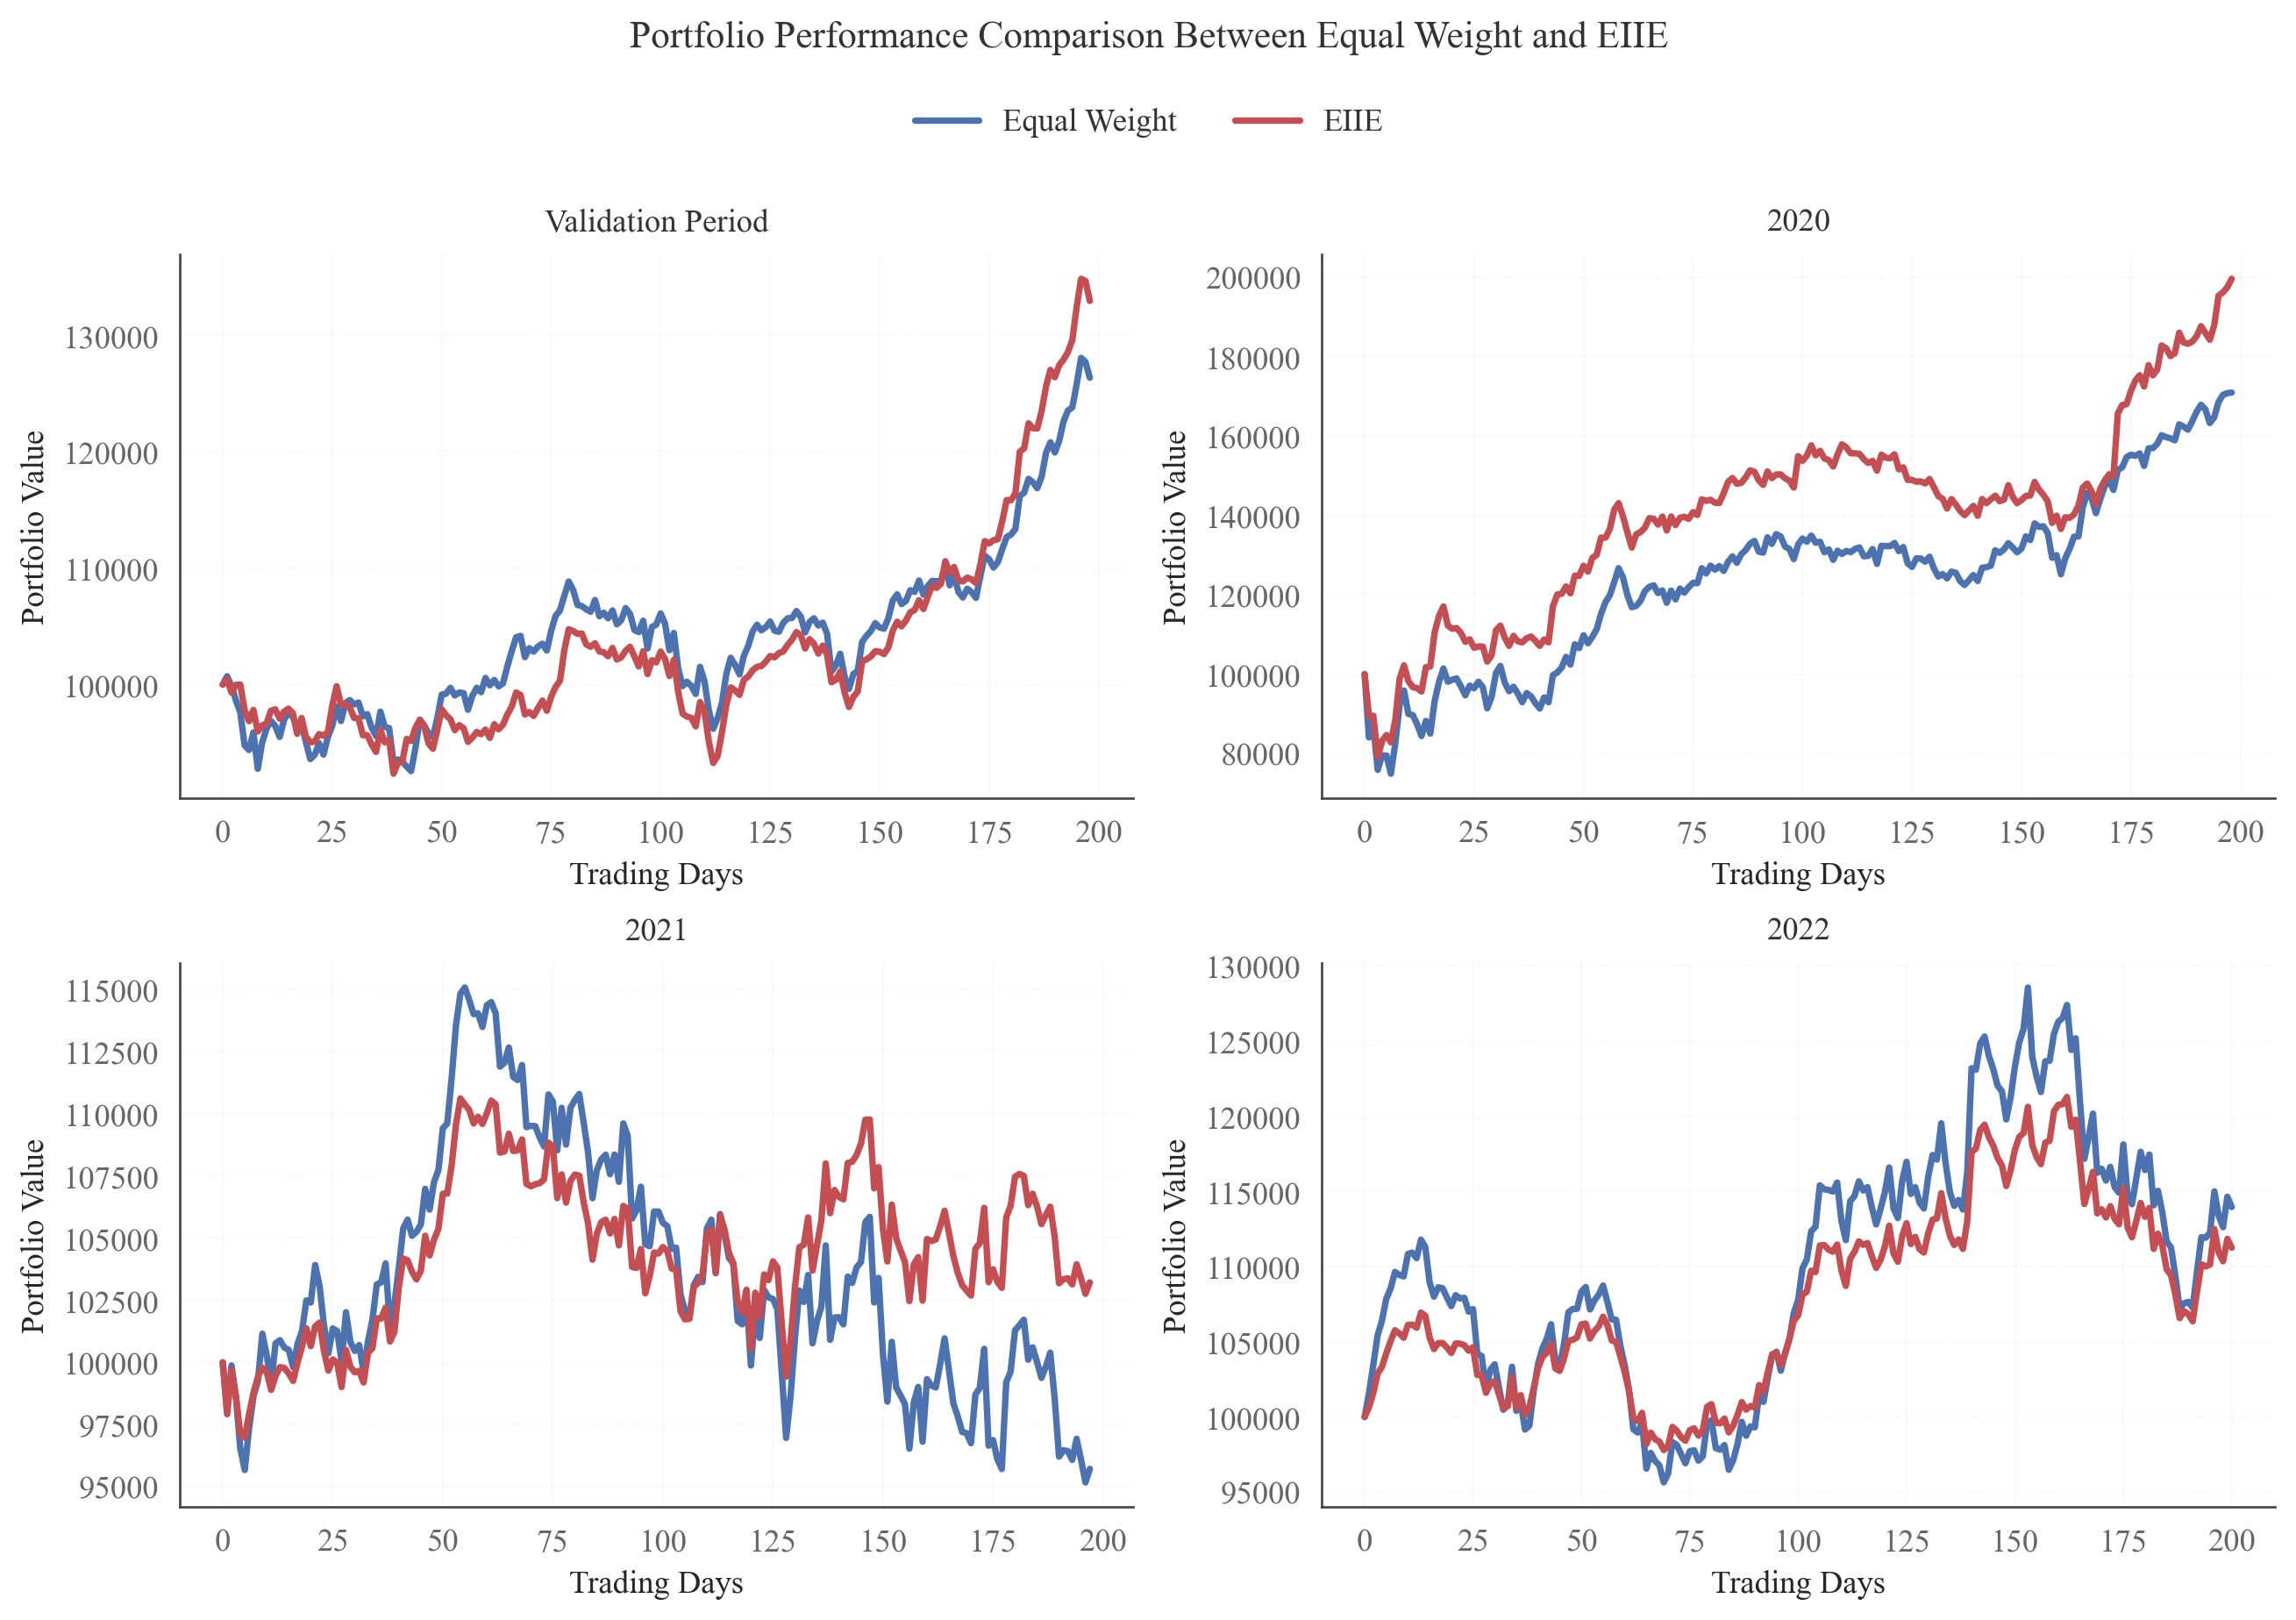

In [92]:
import matplotlib.pyplot as plt
import os
%matplotlib inline 

output_dir = "raw_EIIE_bitcoin_figures"
os.makedirs(output_dir, exist_ok=True)

# Publication-style settings
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 10,

    "lines.linewidth": 2.2,
    "axes.linewidth": 0.8,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "legend.frameon": False,
    "legend.handlelength": 2.2,

    "grid.alpha": 0.20,
    "grid.linewidth": 0.5,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLOR_EW = "#4C72B0"
COLOR_EIIE = "#C44E52"

period_data = [
    ("Validation Period", EW_results["validation"]["value"], EIIE_results["validation"]["value"]),
    ("2020", EW_results["2020"]["value"], EIIE_results["2020"]["value"]),
    ("2021", EW_results["2021"]["value"], EIIE_results["2021"]["value"]),
    ("2022", EW_results["2022"]["value"], EIIE_results["2022"]["value"]),
]

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.2))
axes = axes.flatten()

for ax, (title, ew_values, eiie_values) in zip(axes, period_data):
    x_ew = np.arange(len(ew_values))
    x_eiie = np.arange(len(eiie_values))

    ax.plot(x_ew, ew_values, color=COLOR_EW, label="Equal Weight")
    ax.plot(x_eiie, eiie_values, color=COLOR_EIIE, label="EIIE")

    ax.set_title(title, pad=8)
    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Portfolio Value")

    ax.grid(True, axis="y", linestyle="--")
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

# Shared legend at the top
handles, labels = axes[0].get_legend_handles_labels()
fig_legend = fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02),
    frameon=False
)
apply_times_new_roman_to_legend(fig_legend)

fig.suptitle("Portfolio Performance Comparison Between Equal Weight and EIIE", fontsize=13, y=1.06, fontproperties=TNR_FONT)
for ax in axes:
    apply_times_new_roman(ax)
fig.tight_layout()

fig.savefig(os.path.join(output_dir, "portfolio_performance_comparison.png"), bbox_inches="tight")

plt.show()


We can see that the agent is able to learn a good policy but its performance is worse the more the test period advances into the future. To get a better performance in 2022, for example, the agent should probably be trained again using more recent data.

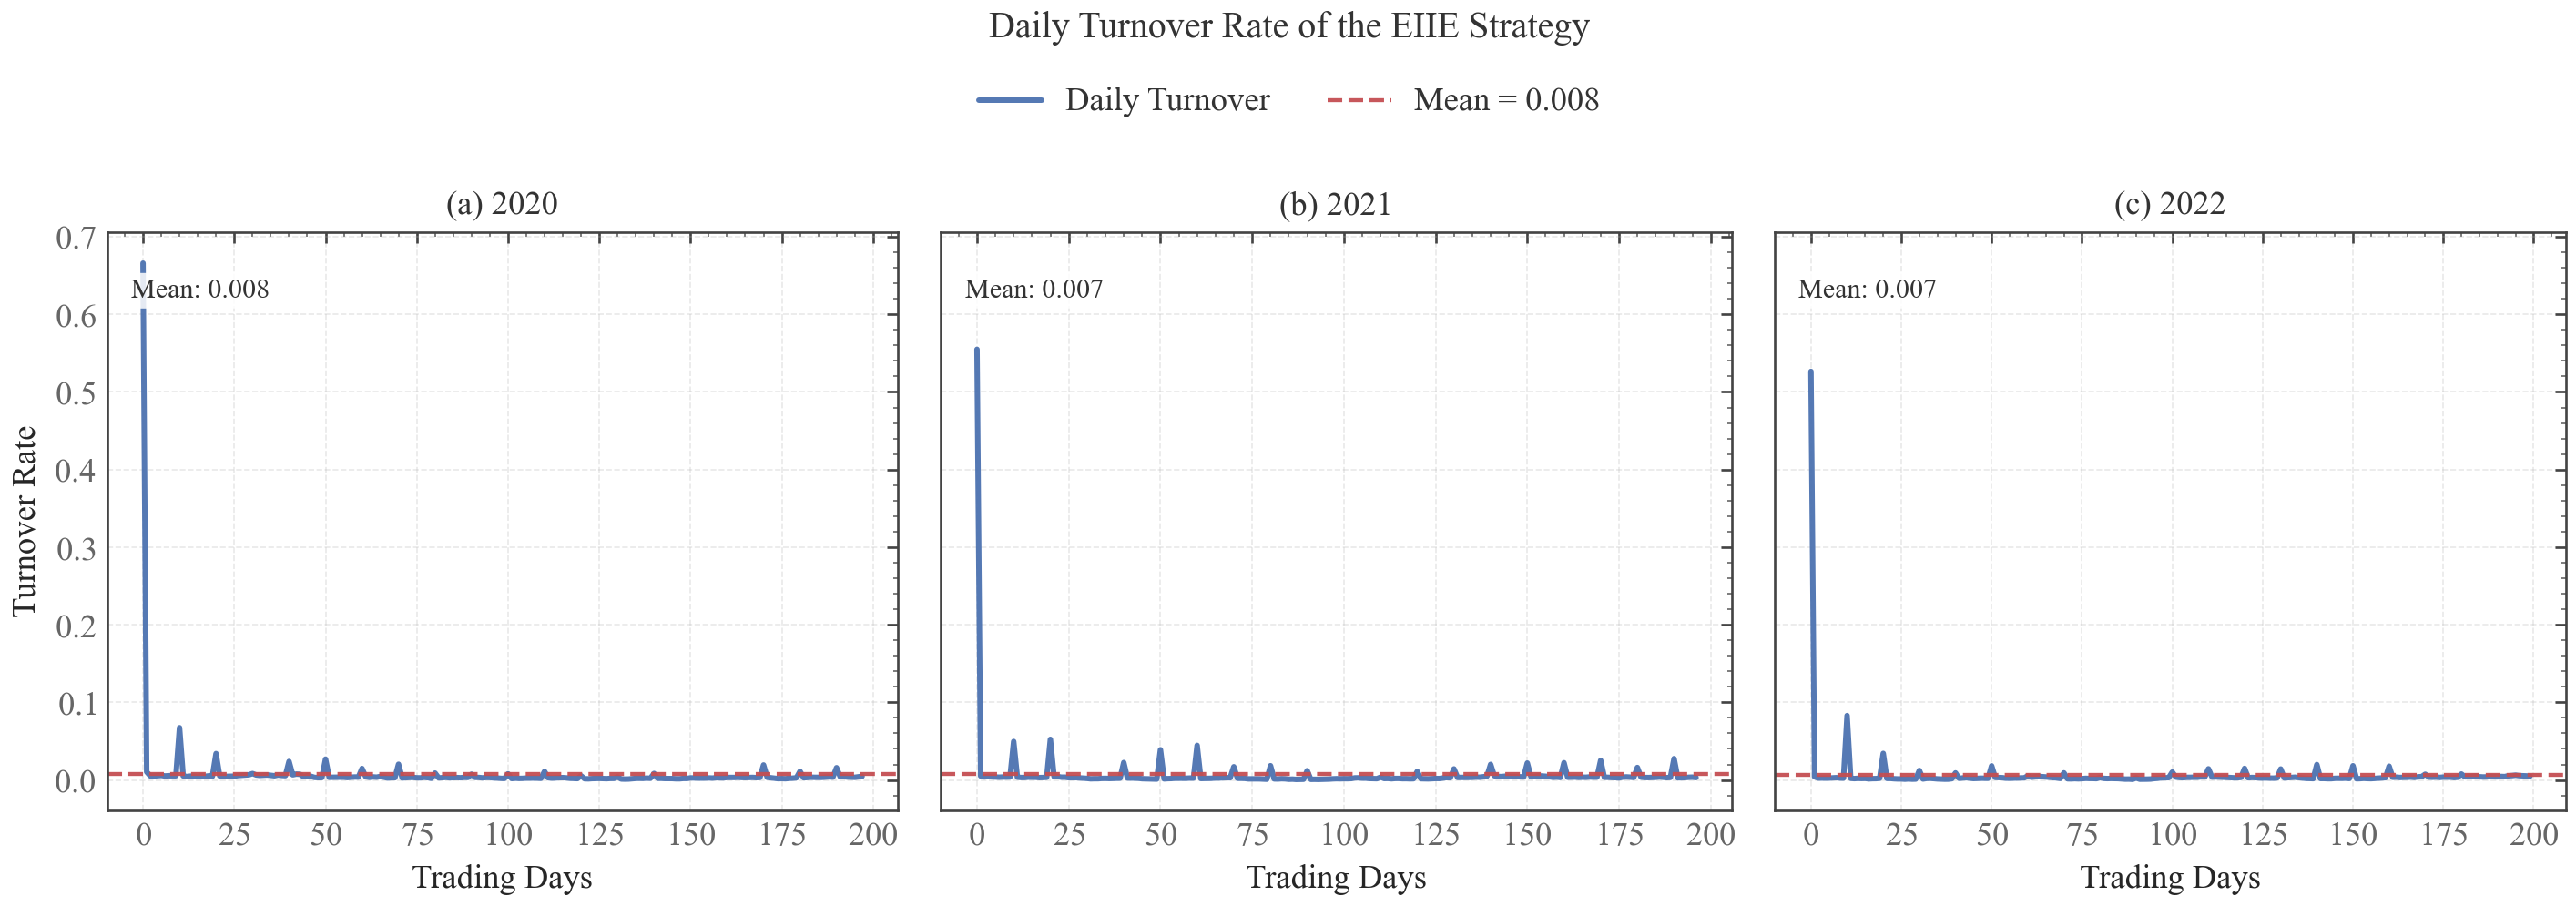

In [93]:
%config InlineBackend.figure_format = "retina"

import os
import numpy as np
import matplotlib.pyplot as plt
import scienceplots

output_dir = "raw_EIIE_bitcoin_figures"
os.makedirs(output_dir, exist_ok=True)

with plt.style.context(["science", "no-latex"]):
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
        "axes.unicode_minus": False,

        "axes.titlesize": 11,
        "axes.labelsize": 11,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
        "legend.fontsize": 9.5,

        "axes.linewidth": 0.9,
        "grid.linewidth": 0.5,
        "grid.alpha": 0.28,
        "lines.linewidth": 1.8,

        "savefig.dpi": 400,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    years = ["2020", "2021", "2022"]
    panel_labels = ["(a)", "(b)", "(c)"]

    fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8), sharey=True)

    line_color = "#4C72B0"
    mean_color = "#C44E52"

    all_turnover = []
    for year in years:
        all_turnover.extend(EIIE_results[year]["turnover"])

    y_min = min(all_turnover)
    y_max = max(all_turnover)
    y_margin = 0.06 * (y_max - y_min) if y_max > y_min else 0.02

    for ax, year, panel in zip(axes, years, panel_labels):
        turnover = np.asarray(EIIE_results[year]["turnover"])
        days = np.arange(len(turnover))
        mean_turnover = turnover.mean()

        ax.plot(
            days,
            turnover,
            color=line_color,
            linewidth=1.8,
            alpha=0.95,
            label="Daily Turnover"
        )

        ax.axhline(
            mean_turnover,
            linestyle="--",
            linewidth=1.3,
            color=mean_color,
            alpha=0.95,
            label=f"Mean = {mean_turnover:.3f}"
        )

        ax.set_title(f"{panel} {year}", pad=6)
        ax.set_xlabel("Trading Days")
        ax.set_ylim(y_min - y_margin, y_max + y_margin)

        if ax is axes[0]:
            ax.set_ylabel("Turnover Rate")

        ax.grid(True, linestyle="--", color="#B0B0B0")
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.8)
            spine.set_color("#444444")

        ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

        ax.text(
            0.03, 0.92,
            f"Mean: {mean_turnover:.3f}",
            transform=ax.transAxes,
            fontsize=9,
            ha="left",
            va="top",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="none",
                alpha=0.85
            )
        )

    handles, labels = axes[0].get_legend_handles_labels()
    fig_legend = fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.04),
        ncol=2,
        frameon=False
    )
    apply_times_new_roman_to_legend(fig_legend)

    fig.suptitle("Daily Turnover Rate of the EIIE Strategy", fontsize=12, y=1.10, fontproperties=TNR_FONT)
    for ax in axes:
        apply_times_new_roman(ax)
    fig.tight_layout()

    fig.savefig(os.path.join(output_dir, "turnover_comparison.png"), bbox_inches="tight")

    plt.show()


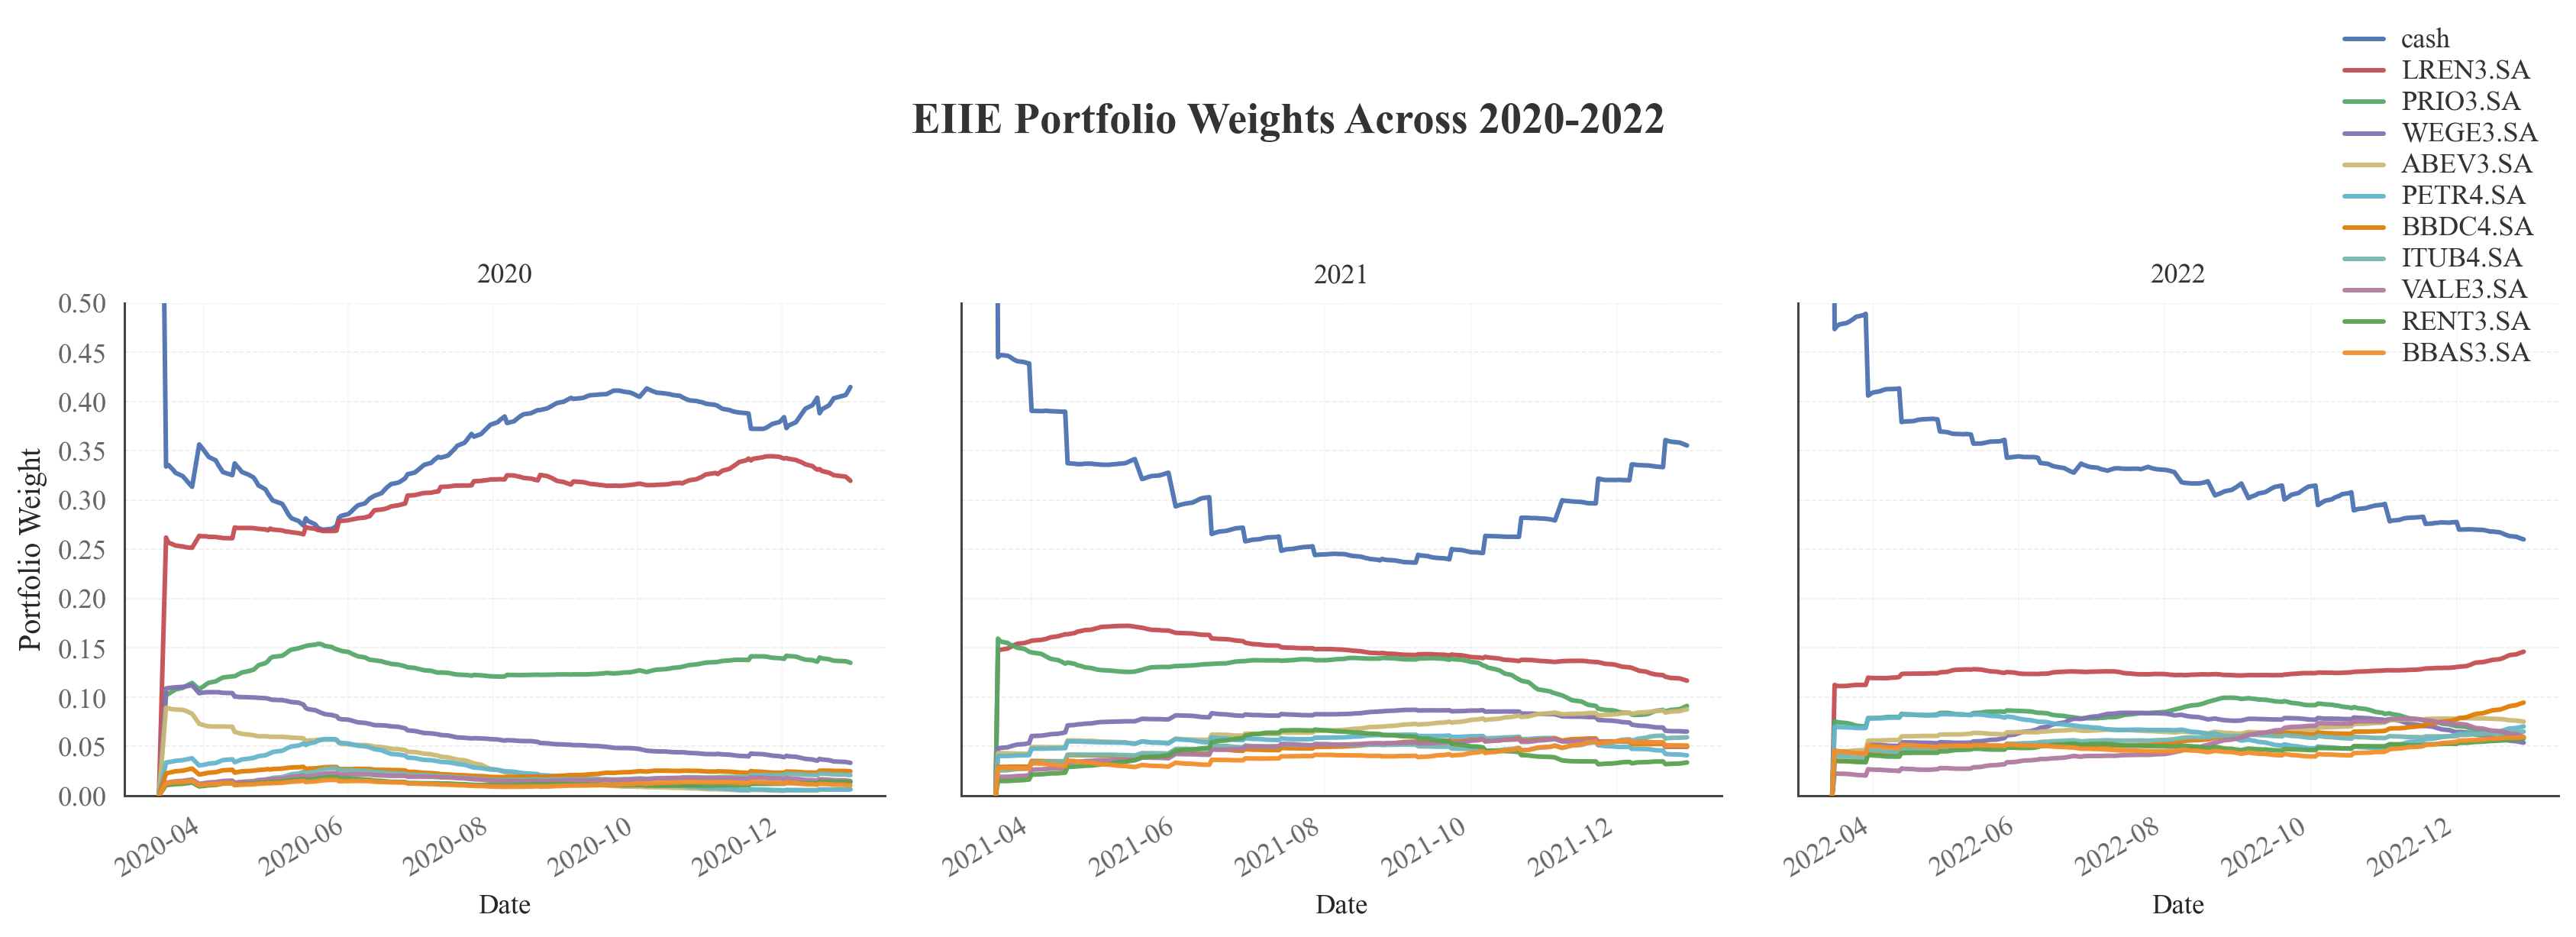

In [95]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%config InlineBackend.figure_format = "retina"

output_dir = "raw_EIIE_bitcoin_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 8.5,

    "axes.linewidth": 0.9,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.22,
    "lines.linewidth": 1.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

HIGHLIGHT_COLORS = [
    "#4C72B0", "#C44E52", "#55A868", "#8172B2", "#CCB974",
    "#64B5CD", "#E17C05", "#76B7B2", "#B07AA1", "#59A14F",
    "#F28E2B", "#8C8C8C"
]

def _prepare_action_plot_data(actions, raw_df, top_k=11, highlight_cash=True):
    actions = np.asarray(actions, dtype=np.float32)

    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = pd.to_datetime(dates[-n_steps:]) if len(dates) >= n_steps else np.arange(n_steps)

    tics = sorted(raw_df["tic"].unique().tolist())
    if actions.shape[1] == len(tics) + 1:
        labels = ["cash"] + tics
    else:
        labels = [f"asset_{i}" for i in range(actions.shape[1])]

    avg_weights = actions.mean(axis=0)
    sorted_idx = np.argsort(avg_weights)[::-1]

    if highlight_cash and labels[0] == "cash":
        cash_idx = 0
        stock_idx = [i for i in sorted_idx if i != cash_idx]
        highlight_idx = [cash_idx] + stock_idx[:top_k]
    else:
        highlight_idx = sorted_idx[:top_k]

    return actions, x_dates, labels, highlight_idx

def plot_actions_triptych(
    result_dict,
    raw_df_dict,
    years=("2020", "2021", "2022"),
    save_path=None,
    top_k=11,
    y_max=0.5,
):
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2), sharey=True)

    for ax, year in zip(axes, years):
        actions, x_dates, labels, highlight_idx = _prepare_action_plot_data(
            result_dict[year]["actions"],
            raw_df_dict[year],
            top_k=top_k,
            highlight_cash=True
        )

        # background assets
        for i in range(actions.shape[1]):
            if i in highlight_idx:
                continue
            ax.plot(
                x_dates,
                actions[:, i],
                color="#C8C8C8",
                linewidth=0.7,
                alpha=0.16,
                zorder=1
            )

        # highlighted assets
        for j, i in enumerate(highlight_idx):
            ax.plot(
                x_dates,
                actions[:, i],
                color=HIGHLIGHT_COLORS[j % len(HIGHLIGHT_COLORS)],
                linewidth=1.8,
                alpha=0.95,
                label=labels[i],
                zorder=3
            )

        ax.set_title(year, pad=8, fontsize=15)
        ax.set_xlabel("Date")
        ax.set_ylim(0.0, y_max)

        ax.grid(True, axis="y", linestyle="--", color="#B0B0B0")
        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#444444")
        ax.spines["bottom"].set_color("#444444")
        ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

        ax.set_yticks(np.arange(0.0, y_max + 1e-9, 0.05))

        if ax is axes[-1]:
            ax.legend(
                loc="upper right",
                bbox_to_anchor=(1.00, 1.6),
                ncol=1,
                frameon=False,
                labelspacing=0.25,
                handlelength=1.8
            )
        apply_times_new_roman(ax)

    axes[0].set_ylabel("Portfolio Weight", fontsize=12)

    fig.suptitle(
        "EIIE Portfolio Weights Across 2020-2022",
        fontsize=17,
        x=0.44,
        y=1.1,
        ha="center",
        fontweight="semibold",
        fontproperties=TNR_FONT
    )


    # Compress whitespace
    fig.subplots_adjust(
        left=0.055,
        right=0.86,
        bottom=0.20,
        top=0.84,
        wspace=0.10
    )


    fig.savefig(save_path, bbox_inches="tight")

    plt.show()


plot_actions_triptych(
    result_dict=EIIE_results,
    raw_df_dict={
        "2020": df_portfolio_2020,
        "2021": df_portfolio_2021,
        "2022": df_portfolio_2022,
    },
    years=("2020", "2021", "2022"),
    save_path=os.path.join(output_dir, "EIIE_weights_triptych.png"),
    top_k=11,
    y_max=0.5
)


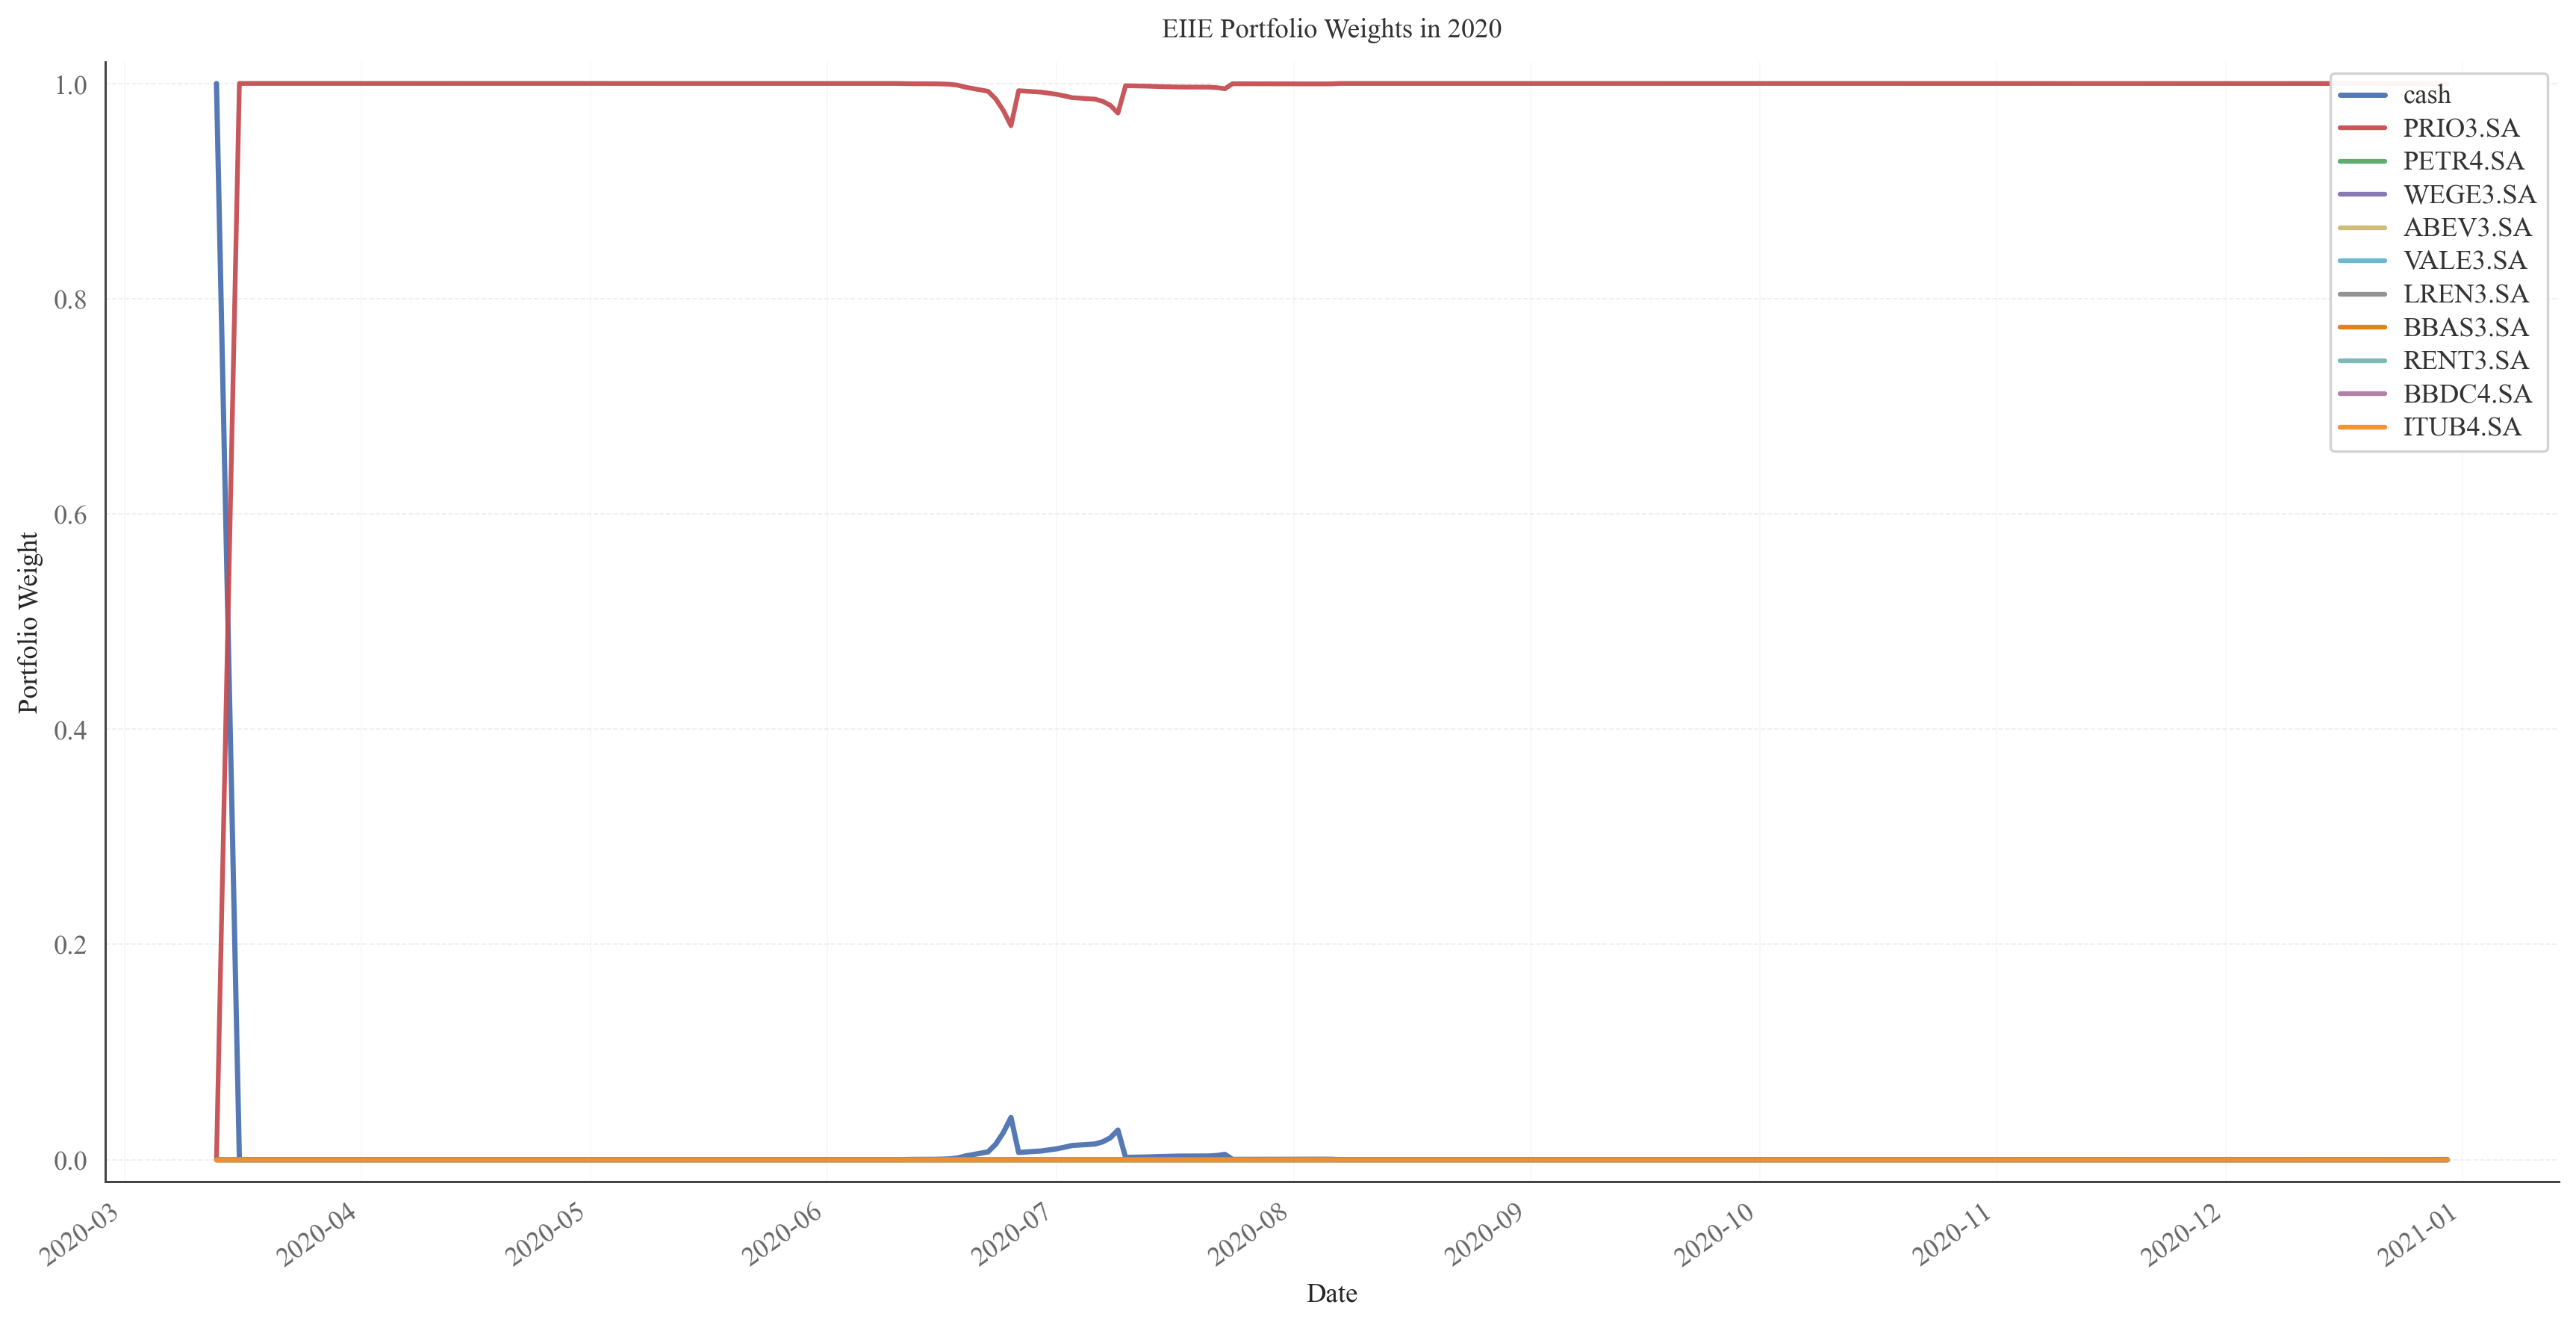

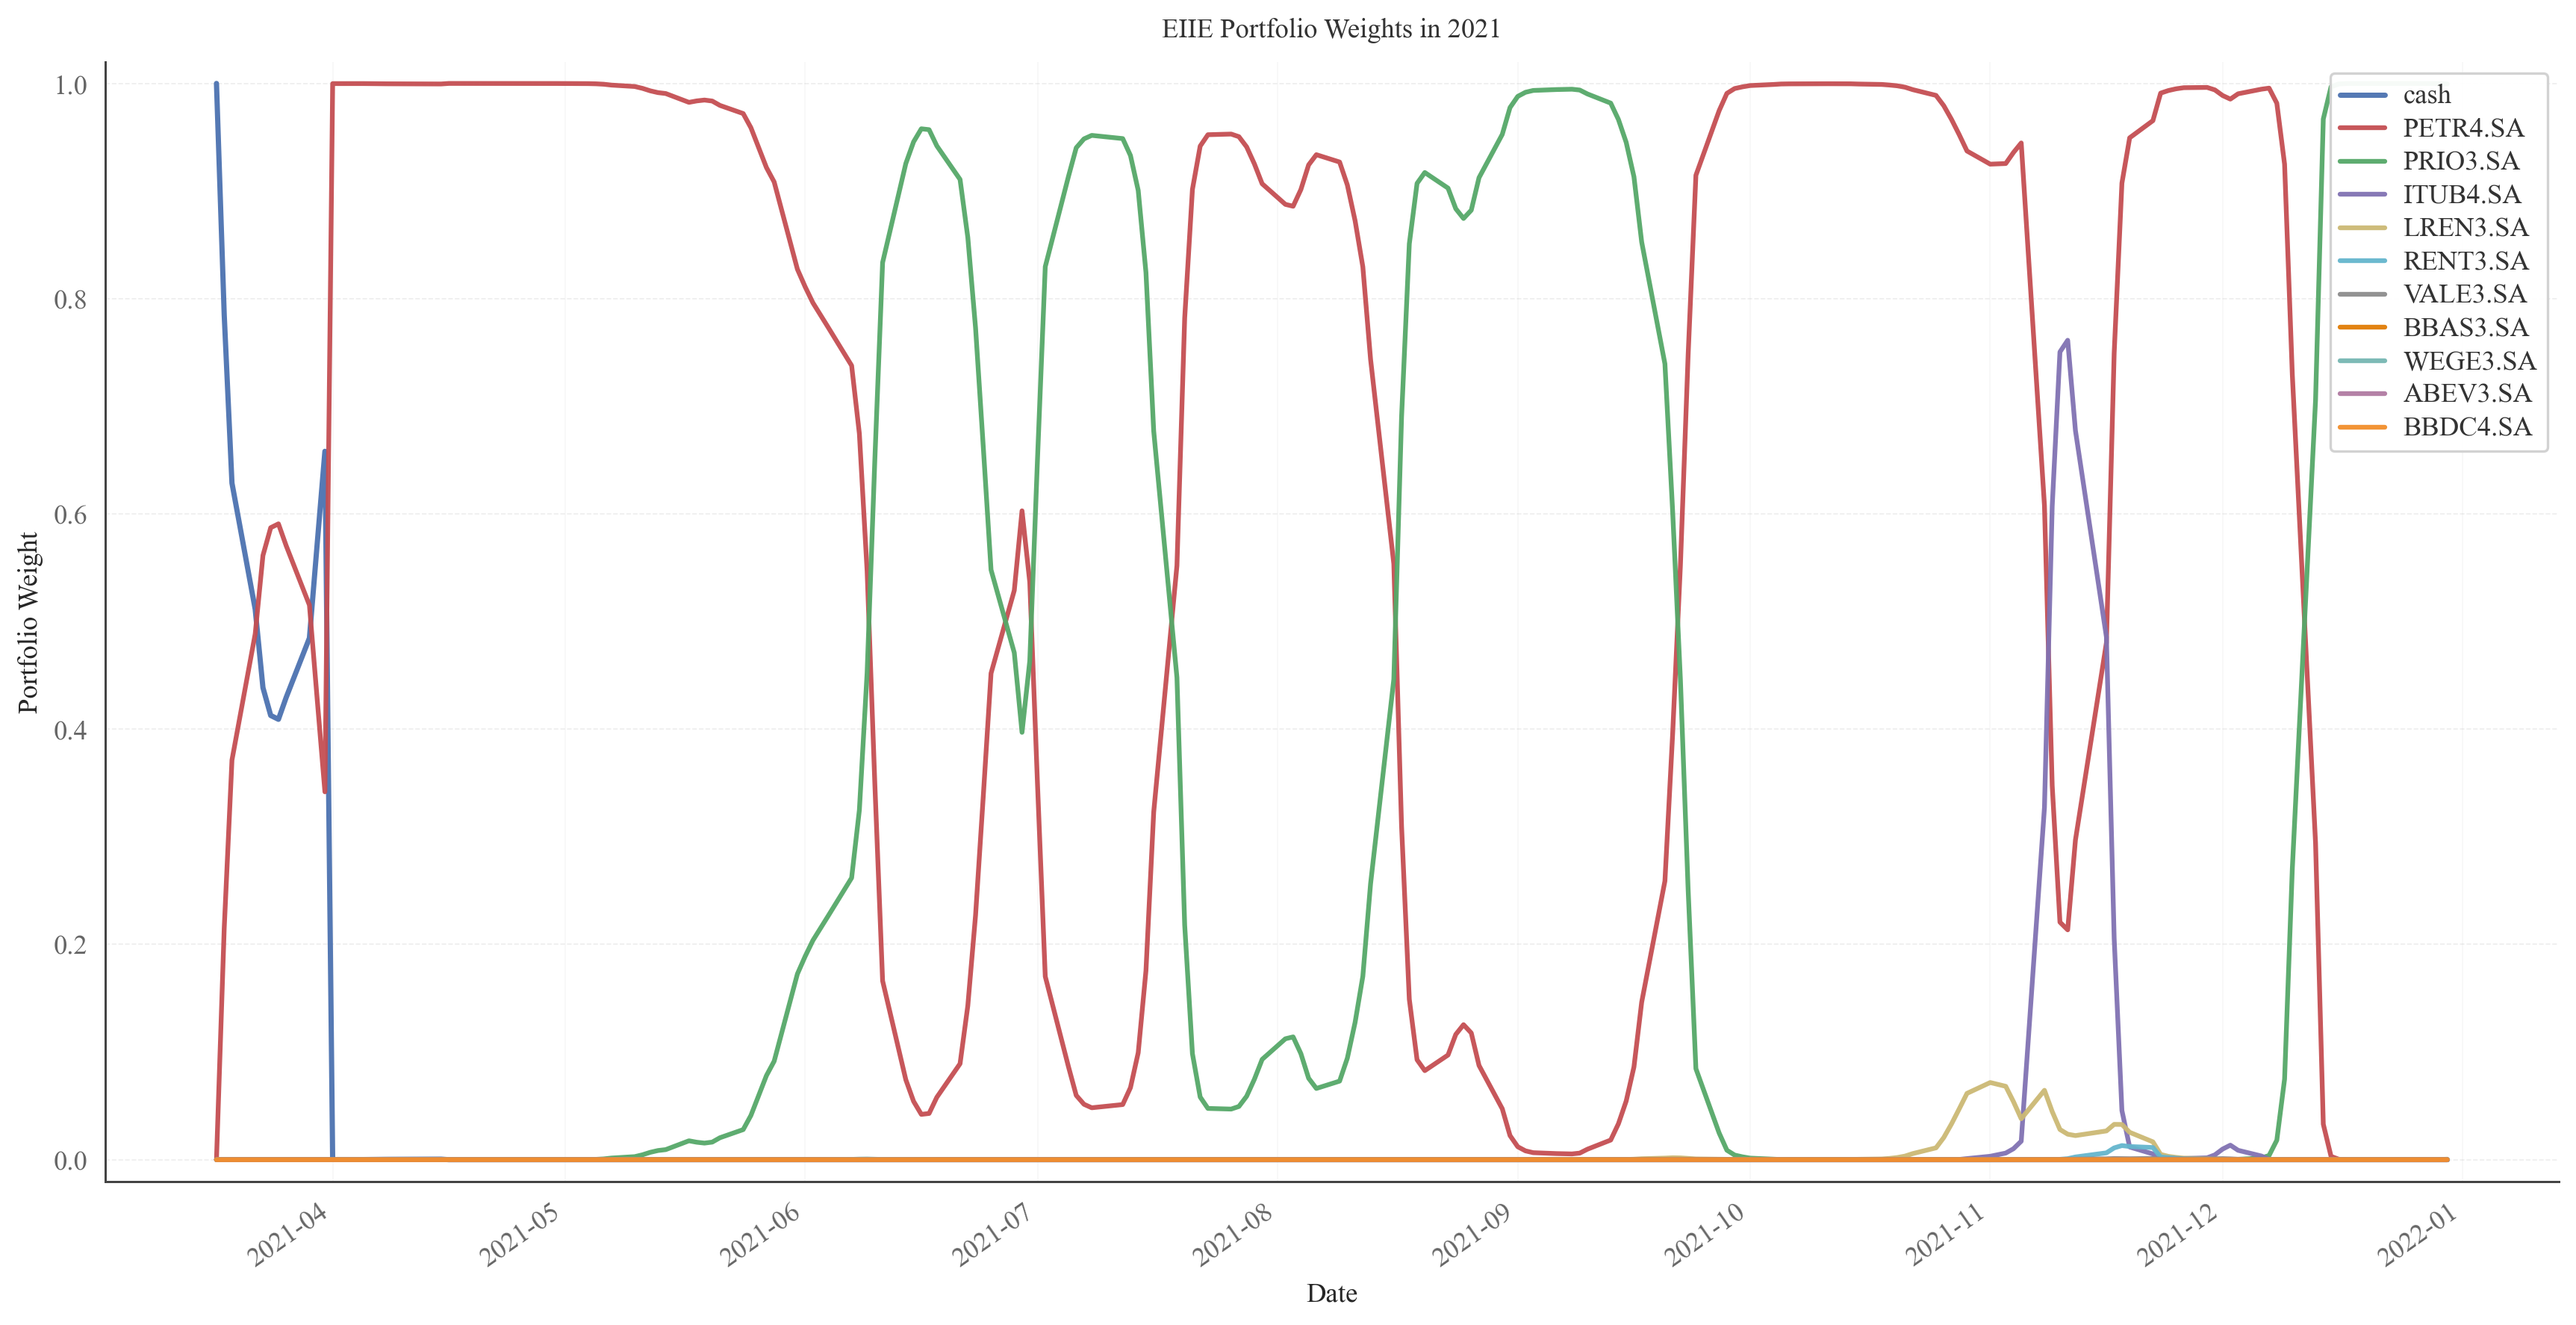

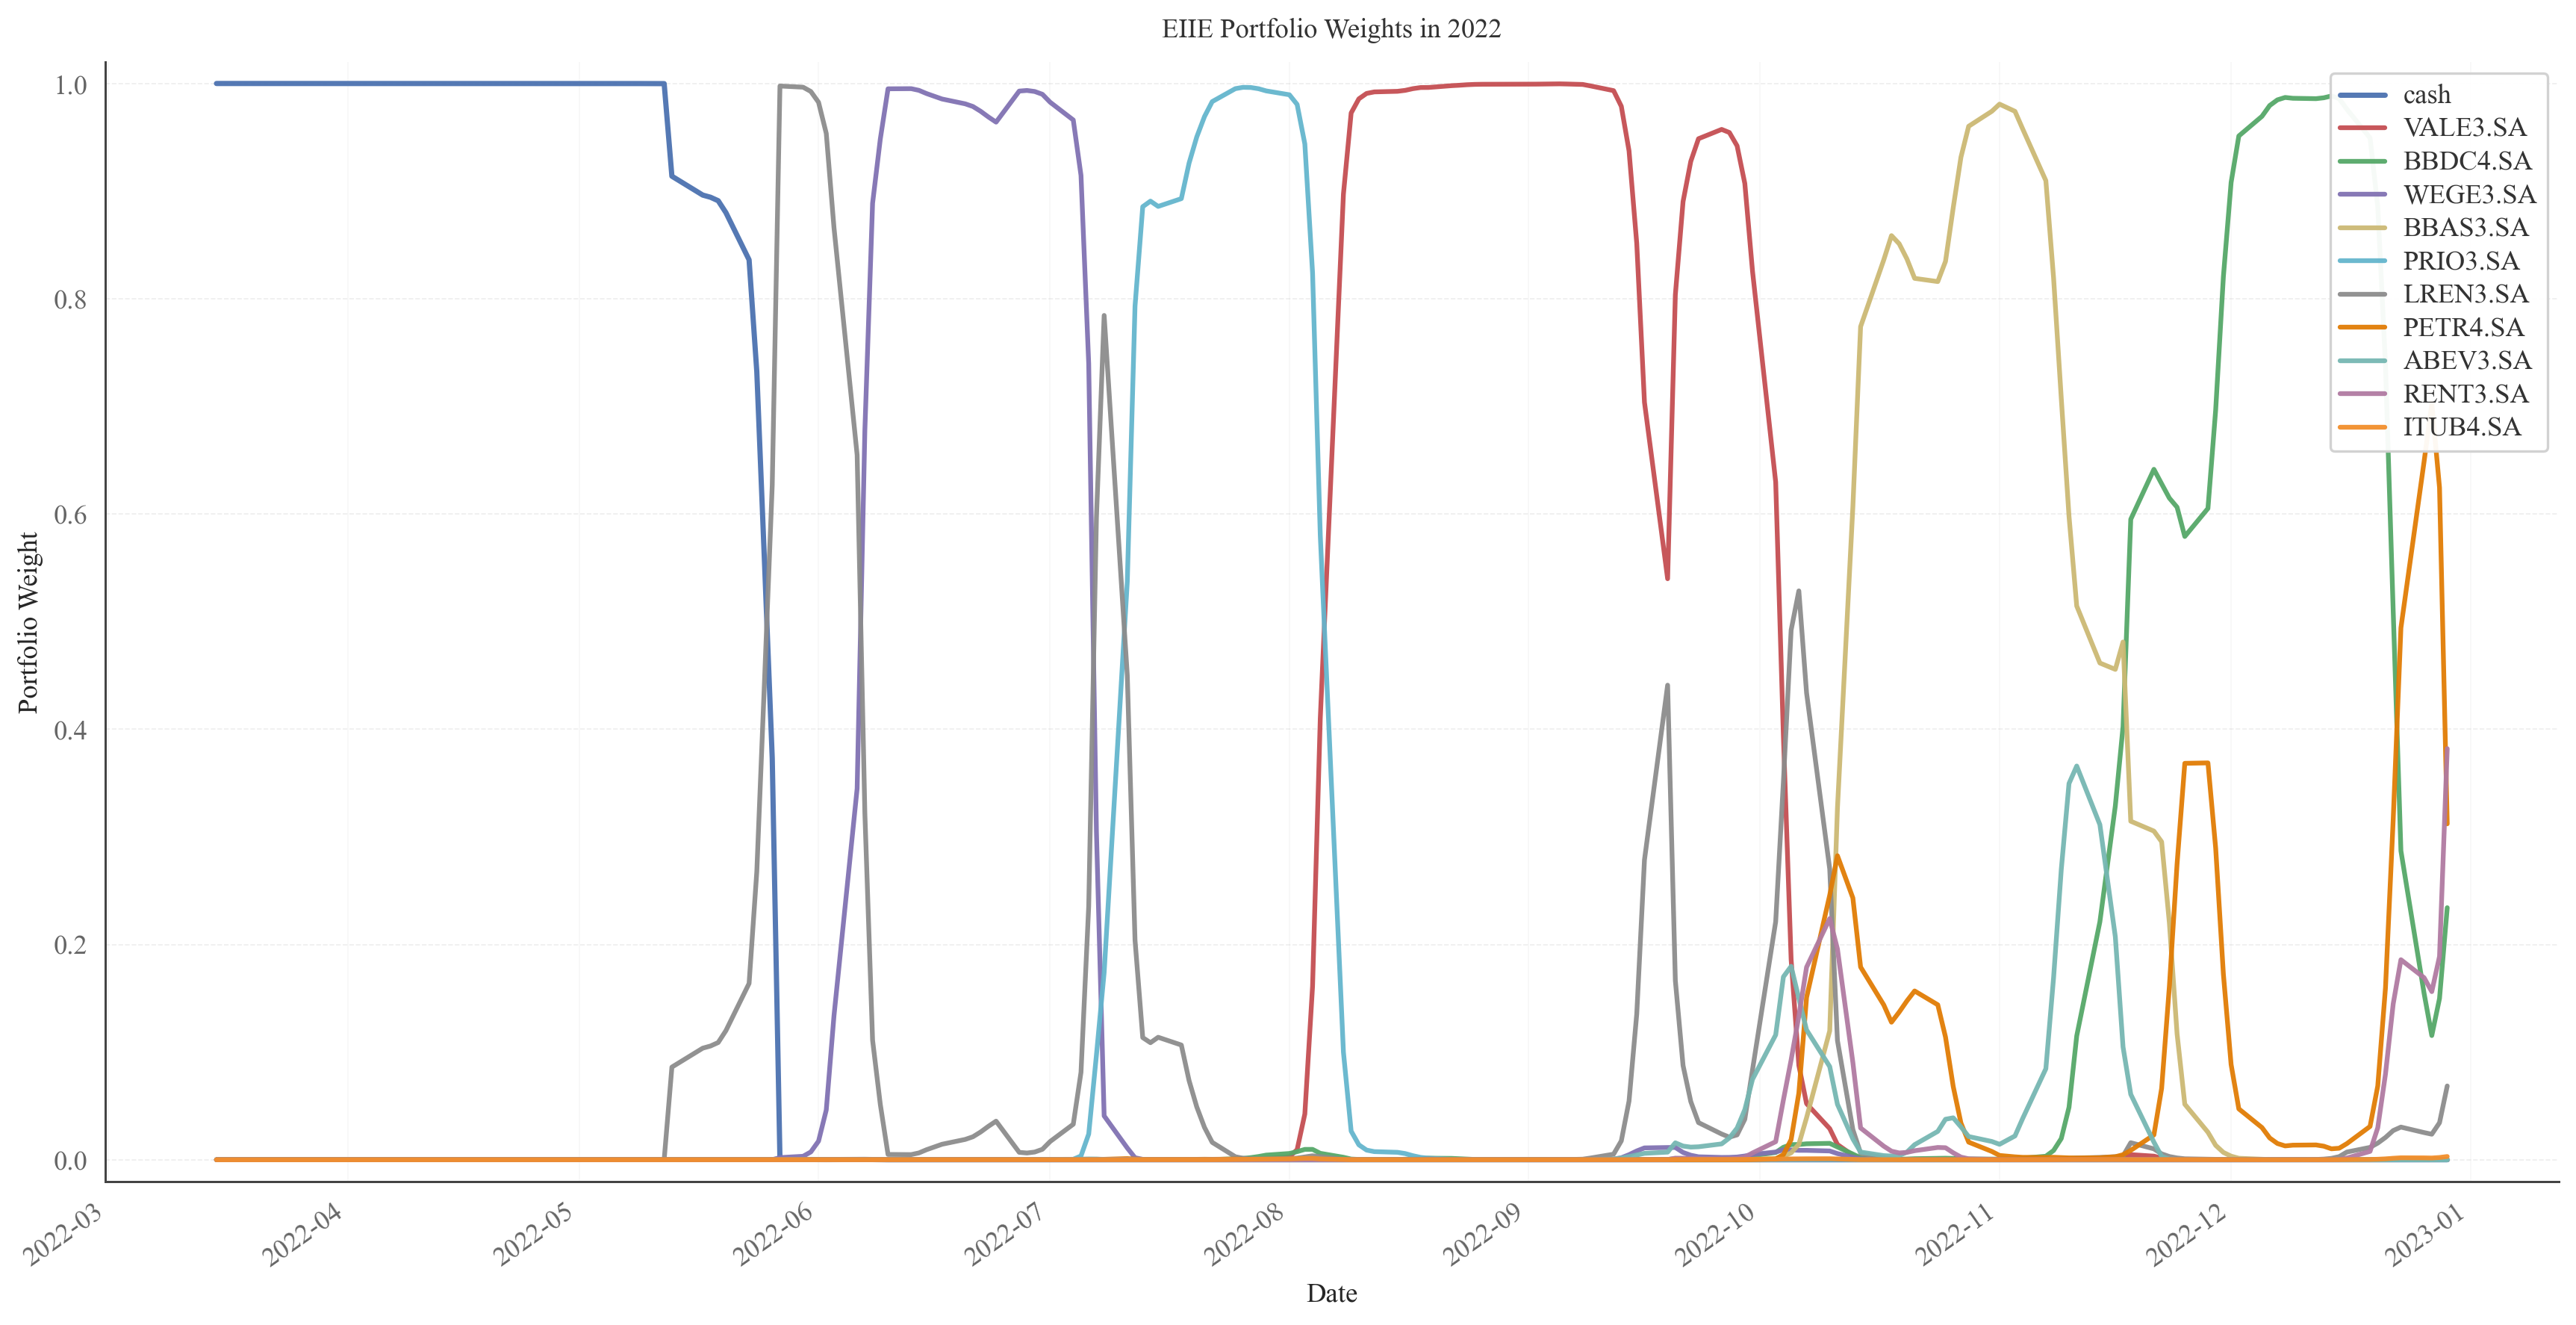

In [84]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%config InlineBackend.figure_format = "retina"

output_dir = "raw_EIIE_bitcoin_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,

    "axes.linewidth": 0.9,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.22,
    "lines.linewidth": 1.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# A restrained academic palette for highlighted assets
HIGHLIGHT_COLORS = [
    "#4C72B0", "#C44E52", "#55A868", "#8172B2", "#CCB974",
    "#64B5CD", "#8C8C8C", "#E17C05", "#76B7B2", "#B07AA1",
    "#F28E2B", "#59A14F"
]

def plot_actions_pretty(
    actions,
    raw_df,
    title,
    save_path=None,
    top_k=11,
    figsize=(14.5, 7.5),
    highlight_cash=True,
):
    actions = np.asarray(actions, dtype=np.float32)

    # 1. Build the date axis
    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = pd.to_datetime(dates[-n_steps:]) if len(dates) >= n_steps else np.arange(n_steps)

    # 2. Build labels
    tics = sorted(raw_df["tic"].unique().tolist())
    if actions.shape[1] == len(tics) + 1:
        labels = ["cash"] + tics
    else:
        labels = [f"asset_{i}" for i in range(actions.shape[1])]

    # 3. Select highlighted assets based on average allocation
    avg_weights = actions.mean(axis=0)
    sorted_idx = np.argsort(avg_weights)[::-1]

    if highlight_cash and labels[0] == "cash":
        cash_idx = 0
        stock_idx = [i for i in sorted_idx if i != cash_idx]
        highlight_idx = [cash_idx] + stock_idx[:top_k]
    else:
        cash_idx = None
        highlight_idx = sorted_idx[:top_k]

    fig, ax = plt.subplots(figsize=figsize)

    # 4. Plot non-highlighted assets in the background
    for i in range(actions.shape[1]):
        if i in highlight_idx:
            continue
        ax.plot(
            x_dates,
            actions[:, i],
            color="#B8B8B8",
            linewidth=0.8,
            alpha=0.18,
            zorder=1
        )

    # 5. Plot highlighted assets, including cash in the same style family
    for j, i in enumerate(highlight_idx):
        color = HIGHLIGHT_COLORS[j % len(HIGHLIGHT_COLORS)]
        ax.plot(
            x_dates,
            actions[:, i],
            color=color,
            linewidth=1.9 if labels[i] != "cash" else 2.1,
            alpha=0.95,
            label=labels[i],
            zorder=3
        )

    # 6. Axes styling
    ax.set_title(title, pad=10)
    ax.set_xlabel("Date")
    ax.set_ylabel("Portfolio Weight")
    ax.set_ylim(-0.02, 1.02)

    ax.grid(True, axis="y", linestyle="--", color="#B0B0B0")
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

    # 7. Format the x-axis as year-month, e.g. 2023-01
    if isinstance(x_dates[0], (np.datetime64, pd.Timestamp)):
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    # 8. Legend in the upper-right corner
    ax.legend(
        loc="upper right",
        ncol=1,
        frameon=True,
        framealpha=0.95,
        facecolor="white",
        edgecolor="#D0D0D0",
        borderpad=0.45,
        labelspacing=0.35,
        handlelength=2.0
    )

    apply_times_new_roman(ax)
    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
        if save_path.lower().endswith(".png"):
            fig.savefig(save_path[:-4] + ".pdf", bbox_inches="tight")

    plt.show()


plot_actions_pretty(
    EIIE_results["2020"]["actions"],
    df_portfolio_2020,
    "EIIE Portfolio Weights in 2020",
    top_k=11
)

plot_actions_pretty(
    EIIE_results["2021"]["actions"],
    df_portfolio_2021,
    "EIIE Portfolio Weights in 2021",
    top_k=11
)

plot_actions_pretty(
    EIIE_results["2022"]["actions"],
    df_portfolio_2022,
    "EIIE Portfolio Weights in 2022",
    top_k=11
)
